# Load data - Data Discovery/Data Quality Checking

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


sales = pd.read_csv("01_Sales_Transactions.csv")
products = pd.read_excel("02_Product_Master.xlsx")
customers = pd.read_excel("03_Customer_Master.xlsx")
campaigns = pd.read_csv("04_Campaign_Data.csv")

# Checking size of each dataset

In [2]:
sales.shape

(50018, 12)

In [3]:
products.shape

(180, 6)

In [4]:
customers.shape

(8001, 5)

In [5]:
campaigns.shape

(14, 7)

# Checking columns and data types

In [6]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50018 entries, 0 to 50017
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       50018 non-null  object 
 1   Order Date     50018 non-null  object 
 2   Customer ID    49878 non-null  object 
 3   Product ID     50018 non-null  object 
 4   Quantity       50018 non-null  int64  
 5   Unit Price     50018 non-null  float64
 6   Discount       50018 non-null  float64
 7   Sales Channel  50018 non-null  object 
 8   State          50018 non-null  object 
 9   Shipping Cost  49953 non-null  float64
 10  Return Status  50018 non-null  object 
 11  Campaign ID    8120 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 4.6+ MB


In [7]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product ID     180 non-null    object 
 1   Product Name   180 non-null    object 
 2   Category       180 non-null    object 
 3   Supplier       180 non-null    object 
 4   Unit Cost      180 non-null    float64
 5   Selling Price  180 non-null    float64
dtypes: float64(2), object(4)
memory usage: 8.6+ KB


In [8]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8001 entries, 0 to 8000
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Customer ID          8001 non-null   object
 1   Customer Segment     8001 non-null   object
 2   Customer Type        8001 non-null   object
 3   State                8001 non-null   object
 4   Acquisition Channel  8001 non-null   object
dtypes: object(5)
memory usage: 312.7+ KB


In [9]:
campaigns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Campaign ID     14 non-null     object 
 1   Campaign Name   14 non-null     object 
 2   Start Date      14 non-null     object 
 3   End Date        14 non-null     object 
 4   Promotion Type  14 non-null     object 
 5   Discount Rate   14 non-null     float64
 6   Sales Channel   14 non-null     object 
dtypes: float64(1), object(6)
memory usage: 916.0+ bytes


# Checking missing values

In [10]:
sales.isna().sum()

,0
Order ID,0
Order Date,0
Customer ID,140
Product ID,0
Quantity,0
Unit Price,0
Discount,0
Sales Channel,0
State,0
Shipping Cost,65


In [11]:
products.isna().sum()

,0
Product ID,0
Product Name,0
Category,0
Supplier,0
Unit Cost,0
Selling Price,0


In [12]:
customers.isna().sum()

,0
Customer ID,0
Customer Segment,0
Customer Type,0
State,0
Acquisition Channel,0


In [13]:
campaigns.isna().sum()

,0
Campaign ID,0
Campaign Name,0
Start Date,0
End Date,0
Promotion Type,0
Discount Rate,0
Sales Channel,0


# Checking duplicates

In [14]:
customers["Customer ID"].duplicated().sum()

np.int64(1)

In [15]:
products["Product ID"].duplicated().sum()

np.int64(0)

In [16]:
campaigns["Campaign ID"].duplicated().sum()

np.int64(0)

In [17]:
sales.duplicated().sum()

np.int64(18)

In [18]:
sales["Order ID"].duplicated().sum()

np.int64(18)

# Checking unique categorical values

In Sales_Transaction

In [19]:
sales["Sales Channel"].unique()

array(['Amazon', 'Website', 'eBay', 'EBAY', 'amazon', 'Amazon AU'],
      dtype=object)

In [20]:
sales["State"].unique()

array(['Victoria', 'Queensland', 'South Australia', 'New South Wales',
       'Tasmania', 'Western Australia', 'Australian Capital Territory',
       'Northern Territory', 'VIC', 'vic', 'NSW', 'wa'], dtype=object)

In [21]:
sales['Return Status'].unique()

array(['Completed', 'Returned'], dtype=object)

In Customer_Master

In [22]:
customers["State"].unique()

array(['Queensland', 'New South Wales', 'Victoria', 'South Australia',
       'Western Australia', 'Northern Territory', 'Tasmania',
       'Australian Capital Territory', 'VIC', 'vic'], dtype=object)

In [23]:
customers["Customer Segment"].unique()

array(['Professional', 'Individual', 'Small Business', 'Student',
       'student', 'STUDENT'], dtype=object)

In [24]:
customers['Acquisition Channel'].unique()

array(['Marketplace', 'Direct', 'Paid Social', 'Email', 'Referral',
       'Organic Search'], dtype=object)

In [25]:
customers['Customer Type'].unique()

array(['New', 'Returning'], dtype=object)

In Campaign_Master

In [26]:
campaigns['Sales Channel'].unique()

array(['Website', 'eBay', 'Amazon'], dtype=object)

In [27]:
campaigns['Campaign Name'].unique()

array(['New Year Refresh', 'Autumn Workspace', 'Mid-Year Marketplace',
       'Winter Essentials', 'Spring Workspace', 'Black Friday',
       'Holiday Sale'], dtype=object)

In [28]:
campaigns['Promotion Type'].unique()

array(['Percentage Discount'], dtype=object)

In Product_Master

In [29]:
products['Category'].unique()

array(['Home Office', 'home office', 'Desk Accessories', 'HOME OFFICE',
       'Lighting', 'Storage & Organisation', 'Home office ',
       'Technology Accessories', 'Lifestyle Products'], dtype=object)

In [30]:
products['Supplier'].unique()

array(['Overseas Supplier C', 'Local Supplier B', 'Local Supplier A',
       'Overseas Supplier D'], dtype=object)

# Checking suspicious numeric values

In [31]:
sales["Quantity"].describe()

,Quantity
count,50018.000000
mean,1.859131
std,6.123943
min,-9.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,999.000000


In [32]:
sales["Discount"].describe()

,Discount
count,50018.000000
mean,0.026488
std,0.053176
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,0.200000


In [33]:
sales["Shipping Cost"].describe()

,Shipping Cost
count,49953.000000
mean,15.411847
std,10.395441
min,5.100000
25%,7.620000
50%,12.470000
75%,19.840000
max,115.360000


In [34]:
sales[sales["Quantity"] < 0]

,Order ID,Order Date,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,Campaign ID
106,O009948,26/10/2025,C07425,P1103,-2,11.41,0.00,Amazon,Queensland,17.00,Returned,NaN
118,O012082,23/06/2024,C00191,P1103,-1,11.41,0.00,Website,New South Wales,6.99,Returned,NaN
123,O012971,15/10/2024,C00028,P1103,-1,11.41,0.10,Website,Western Australia,15.56,Returned,NaN
138,O014764,11/07/2024,NaN,P1103,-3,11.41,0.00,Amazon,Victoria,17.64,Returned,NaN
248,O026709,18/06/2024,C05074,P1103,-1,11.41,0.00,Amazon,New South Wales,6.17,Returned,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
49631,O015204,04/03/2024,C01801,P1149,-1,351.37,0.00,Amazon,Victoria,6.11,Returned,NaN
49669,O023865,10/10/2025,C01611,P1149,-2,351.37,0.00,Amazon,South Australia,18.16,Returned,NaN
49672,O025083,09/12/2024,C04066,P1149,-3,351.37,0.10,Website,Victoria,17.30,Returned,CMP007
49845,O019024,08/08/2024,C00531,P1012,-1,361.02,0.05,Amazon,New South Wales,8.14,Returned,NaN


In [35]:
sales[sales["Quantity"] > 100]

,Order ID,Order Date,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,Campaign ID
7521,O020003,22/10/2025,C02137,P1081,500,49.68,0.00,eBay,Victoria,6.13,Completed,NaN
39002,O010002,28/05/2025,C02474,P1167,999,258.06,0.00,Website,Queensland,54.93,Completed,NaN
46439,O030004,03/09/2024,C04498,P1121,750,298.42,0.15,Amazon,Queensland,26.91,Completed,CMP005


# Checking relationships

In [36]:
sales["Product ID"].isin(products["Product ID"]).value_counts()

,count
Product ID,
True,50018


In [37]:
sales["Customer ID"].isin(customers["Customer ID"]).value_counts()

,count
Customer ID,
True,49878
False,140


In [38]:
sales["Campaign ID"].isin(campaigns["Campaign ID"]).value_counts()

,count
Campaign ID,
False,41898
True,8120


# Checking order date

In [39]:
sales[sales["Order Date"].isna()]

,Order ID,Order Date,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,Campaign ID


In [40]:
sales["Order Date"].min()

'01/01/2024'

In [41]:
sales["Order Date"].max()

'31/13/2024'

In [42]:
sales[
    (sales["Order Date"] < "2024-01-01") |
    (sales["Order Date"] > "2025-12-31")
]

,Order ID,Order Date,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,Campaign ID
0,O000115,27/02/2024,C02782,P1103,3,11.41,0.0,Amazon,Victoria,17.66,Completed,NaN
1,O000376,29/08/2024,C07071,P1103,1,11.41,0.0,Amazon,Queensland,8.99,Completed,NaN
2,O000521,04/10/2025,C01655,P1103,3,11.41,0.0,Website,Victoria,20.12,Completed,NaN
3,O000544,20/06/2025,C04717,P1103,4,11.41,0.0,Amazon,Queensland,41.37,Completed,NaN
4,O000580,10/11/2025,C00724,P1103,3,11.41,0.0,Website,South Australia,22.43,Completed,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
50013,O048521,28/07/2024,C02169,P1012,1,361.02,0.0,Amazon,New South Wales,7.17,Completed,NaN
50014,O048850,05/10/2024,C04344,P1012,3,361.02,0.0,Amazon,South Australia,22.85,Completed,NaN
50015,O049106,17/03/2025,C01827,P1012,3,361.02,0.0,eBay,Victoria,20.15,Completed,NaN
50016,O049633,03/08/2025,C01315,P1012,3,361.02,0.0,Website,Queensland,26.09,Completed,NaN


# Checking Product Name -Consistency and Duplicates

In [43]:
products["Product Name"].unique()

array(['Premium Office Chair 01', 'Ergonomic Standing Desk 02',
       'Premium Keyboard Tray 03', 'Minimal Desk Mat 04',
       'Essential Office Chair 05', 'Ergonomic Footrest 06',
       'Adjustable Standing Desk 07', 'Ergonomic Desk Mat 08',
       'Essential Standing Desk 09', 'Classic Monitor Stand 10',
       'Ergonomic Monitor Stand 11', 'Premium Desk Mat 12',
       'Classic Monitor Stand 13', 'Essential Keyboard Tray 14',
       'Adjustable Office Chair 15', 'Premium Footrest 16',
       'Minimal Monitor Stand 17', 'Premium Office Chair 18',
       'Modern Office Chair 19', 'Premium Desk Mat 20',
       'Portable Keyboard Tray 21', 'Compact Monitor Stand 22',
       'Ergonomic Keyboard Tray 23', 'Premium Footrest 24',
       'Adjustable Keyboard Tray 25', 'Compact Desk Mat 26',
       'Modern Keyboard Tray 27', 'Classic Office Chair 28',
       'Essential Monitor Stand 29', 'Modern Office Chair 30',
       'Minimal Keyboard Tray 31', 'Ergonomic Keyboard Tray 32',
       'Smar

In [44]:
products["Product Name"].str.strip().str.lower().unique()

array(['premium office chair 01', 'ergonomic standing desk 02',
       'premium keyboard tray 03', 'minimal desk mat 04',
       'essential office chair 05', 'ergonomic footrest 06',
       'adjustable standing desk 07', 'ergonomic desk mat 08',
       'essential standing desk 09', 'classic monitor stand 10',
       'ergonomic monitor stand 11', 'premium desk mat 12',
       'classic monitor stand 13', 'essential keyboard tray 14',
       'adjustable office chair 15', 'premium footrest 16',
       'minimal monitor stand 17', 'premium office chair 18',
       'modern office chair 19', 'premium desk mat 20',
       'portable keyboard tray 21', 'compact monitor stand 22',
       'ergonomic keyboard tray 23', 'premium footrest 24',
       'adjustable keyboard tray 25', 'compact desk mat 26',
       'modern keyboard tray 27', 'classic office chair 28',
       'essential monitor stand 29', 'modern office chair 30',
       'minimal keyboard tray 31', 'ergonomic keyboard tray 32',
       'smar

In [45]:
products.groupby(
    products["Product Name"].str.strip().str.lower()
)["Product Name"].nunique()

,Product Name
Product Name,
adjustable backpack 27,1
adjustable cable clip 11,1
adjustable charging dock 20,1
adjustable cushion 02,1
adjustable desk pad 19,1
...,...
smart usb hub 11,1
smart usb hub 14,1
smart webcam cover 18,1


**Data Cleaning**

# Data Cleaning

In [46]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [47]:
base = "/content/drive/MyDrive/Harbour_Co_Data/"

In [48]:
sales_raw = pd.read_csv(base + "01_Sales_Transactions.csv")

products_raw = pd.read_excel(base + "02_Product_Master.xlsx")

customers_raw = pd.read_excel(base + "03_Customer_Master.xlsx")

campaigns_raw = pd.read_csv(base + "04_Campaign_Data.csv")

In [49]:
print(sales_raw.shape)
print(products_raw.shape)
print(customers_raw.shape)
print(campaigns_raw.shape)

(50018, 12)
(180, 6)
(8001, 5)
(14, 7)


**Dropping 18 duplicates in Sales_Transactions dataset**

In [50]:
# Check exact duplicate rows
sales.duplicated().sum()

np.int64(18)

In [51]:
# Remove confirmed exact duplicate rows
sales = sales.drop_duplicates().copy()

In [52]:
# Validate
sales.duplicated().sum()

np.int64(0)

In [53]:
sales.shape

(50000, 12)

**Standardise categorical values**

States

In [54]:
state_mapping = {
    "VIC": "Victoria",
    "vic": "Victoria",
    "NSW": "New South Wales",
    "WA": "Western Australia",
    "wa": "Western Australia"
}

sales["State"] = sales["State"].replace(state_mapping)
customers["State"] = customers["State"].replace(state_mapping)

In [55]:
sales["State"].unique()

array(['Victoria', 'Queensland', 'South Australia', 'New South Wales',
       'Tasmania', 'Western Australia', 'Australian Capital Territory',
       'Northern Territory'], dtype=object)

In [56]:
customers['State'].unique()

array(['Queensland', 'New South Wales', 'Victoria', 'South Australia',
       'Western Australia', 'Northern Territory', 'Tasmania',
       'Australian Capital Territory'], dtype=object)

Sales Channels

In [57]:
channel_mapping = {
    "amazon": "Amazon",
    "Amazon AU": "Amazon",
    "EBAY": "eBay"
}

sales["Sales Channel"] = sales["Sales Channel"].replace(channel_mapping)
campaigns["Sales Channel"] = campaigns["Sales Channel"].replace(channel_mapping)

In [58]:
sales["Sales Channel"].unique()

array(['Amazon', 'Website', 'eBay'], dtype=object)

In [59]:
campaigns["Sales Channel"].unique()

array(['Website', 'eBay', 'Amazon'], dtype=object)

Customer segment

In [60]:
customers["Customer Segment"] = (
    customers["Customer Segment"]
    .str.strip()
    .str.title()
)

In [61]:
customers["Customer Segment"].unique()

array(['Professional', 'Individual', 'Small Business', 'Student'],
      dtype=object)

Product category

In [62]:
products["Category"] = (
    products["Category"]
    .str.strip()
    .str.title()
)

In [63]:
products["Category"].unique()

array(['Home Office', 'Desk Accessories', 'Lighting',
       'Storage & Organisation', 'Technology Accessories',
       'Lifestyle Products'], dtype=object)

Product Name

In [64]:
products["Product Name"] = products["Product Name"].str.strip()
products["Product Name"].nunique()

180

**Duplicate Customer ID in Customer_Master**

In [65]:
customers[customers["Customer ID"].duplicated(keep=False)]

,Customer ID,Customer Segment,Customer Type,State,Acquisition Channel
300,C00301,Student,New,New South Wales,Marketplace
8000,C00301,Student,New,New South Wales,Marketplace


In [66]:
# Because these two rows are similar so we remove the other one
customers = customers.drop_duplicates().copy()

In [67]:
customers["Customer ID"].duplicated().sum()

np.int64(0)

**Missing values**

Shipping cost

In [68]:
sales["Shipping Cost"].isna().sum()

np.int64(65)

In [69]:
sales["Shipping Cost Imputed"] = sales["Shipping Cost"].isna()

In [70]:
sales["Shipping Cost Imputed"].value_counts()

,count
Shipping Cost Imputed,
False,49935
True,65


In [71]:
# Calculate the mean by State + Sales Channel
shipping_median = (
    sales.groupby(["State", "Sales Channel"])["Shipping Cost"]
    .transform("median")
)

In [72]:
# Filling 65 missing values
sales["Shipping Cost"] = sales["Shipping Cost"].fillna(shipping_median)

In [73]:
# Validate
sales["Shipping Cost"].isna().sum()

np.int64(0)

In [74]:
# checking flagged values
sales["Shipping Cost Imputed"].sum()

np.int64(65)

Customer IDs

In [75]:
sales["Customer ID"].isna().sum()

# Missing Customer IDs are retained to preserve valid transactions and will be treated as Unknown Customer during analysis.

np.int64(140)

Campaign ID

In [76]:
sales["Campaign ID"].isna().sum()

# Missing Campaign IDs are retained because they may represent transactions that were not associated with a campaign. They will be treated as No Campaign during analysis.

np.int64(41880)

**Order Date - Inconsistent format & unvalid date**

In [77]:
# Parse Order Date - tự nhận diện cả DD/MM/YYYY lẫn YYYY-MM-DD
sales["Order Date Parsed"] = pd.to_datetime(
    sales["Order Date"],
    format="mixed",
    dayfirst=True,      # ưu tiên đọc ngày trước khi format ambiguous
    errors="coerce"      # ngày không hợp lệ -> NaT thay vì lỗi crash
)

# Kiểm tra các dòng bị lỗi
sales[sales["Order Date Parsed"].isna()]

,Order ID,Order Date,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,Campaign ID,Shipping Cost Imputed,Order Date Parsed
10909,O004322,31/13/2024,C05216,P1082,1,62.49,0.00,Amazon,New South Wales,8.06,Completed,NaN,False,NaT
35157,O017322,2025-02-30,C06489,P1042,1,218.76,0.15,Amazon,Queensland,8.10,Completed,CMP005,False,NaT


In [78]:
# Loại 2 dòng không thể khôi phục (chỉ 0.004% dữ liệu, không đáng kể)
sales = sales[sales["Order Date Parsed"].notna()].copy()

# Validate lại
sales["Order Date Parsed"].isna().sum()

np.int64(0)

In [79]:
sales = sales.drop(columns=["Order Date"]).rename(columns={"Order Date Parsed": "Order Date"})

**Negative quantity**

In [80]:
# Decision: Giữ nguyên Quantity âm, không chuyển sang trị tuyệt đối
# Đối chiếu với Return Status để xác nhận tính nhất quán

pd.crosstab(sales["Quantity"] < 0, sales["Return Status"])

Return Status,Completed,Returned
Quantity,,
False,49092,0
True,0,906


In [81]:
# Kiểm tra các dòng lệch để quyết định có cần flag riêng không
mismatch = sales[
    ((sales["Quantity"] < 0) & (sales["Return Status"] != "Returned")) |
    ((sales["Quantity"] >= 0) & (sales["Return Status"] == "Returned"))
]
mismatch

,Order ID,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,Campaign ID,Shipping Cost Imputed,Order Date


**Extreme Outlier quantity**

In [82]:
sales[sales["Quantity"] > 100]

,Order ID,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,Campaign ID,Shipping Cost Imputed,Order Date
7521,O020003,C02137,P1081,500,49.68,0.00,eBay,Victoria,6.13,Completed,NaN,False,2025-10-22
39002,O010002,C02474,P1167,999,258.06,0.00,Website,Queensland,54.93,Completed,NaN,False,2025-05-28
46439,O030004,C04498,P1121,750,298.42,0.15,Amazon,Queensland,26.91,Completed,CMP005,False,2024-09-03


Handling Extreme Quantity Values

Harbour & Co operates under a B2C business model, where individual transactions are expected to represent consumer purchases rather than large-scale wholesale or bulk orders.

The Quantity distribution shows that the median transaction quantity is 1 unit and the third quartile is 2 units, while three records contain unusually large quantities of 500, 750 and 999 units.

Given the B2C scope of the analysis, these extreme values are considered data-entry anomalies rather than representative customer purchases. These records are removed to prevent them from disproportionately affecting sales and profitability analysis.

In [83]:
extreme_quantity = sales["Quantity"] > 100

print("Extreme quantity records:", extreme_quantity.sum())

sales = sales[~extreme_quantity].copy()

print("Sales shape after removing extreme quantities:", sales.shape)

Extreme quantity records: 3
Sales shape after removing extreme quantities: (49995, 13)


**Post Cleaning Validation**

In [84]:
print("Sales:", sales.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Campaigns:", campaigns.shape)

print("\nMissing values:")
print(sales.isna().sum())

print("\nExact duplicate rows:")
print(sales.duplicated().sum())

print("\nDuplicate Customer IDs:")
print(customers["Customer ID"].duplicated().sum())

print("\nInvalid Order Dates:")
print(sales["Order Date"].isna().sum())

print("\nNegative quantities:")
print((sales["Quantity"] < 0).sum())

print("\nExtreme quantities > 100:")
print((sales["Quantity"] > 100).sum())

Sales: (49995, 13)
Products: (180, 6)
Customers: (8000, 5)
Campaigns: (14, 7)

Missing values:
Order ID                     0
Customer ID                140
Product ID                   0
Quantity                     0
Unit Price                   0
Discount                     0
Sales Channel                0
State                        0
Shipping Cost                0
Return Status                0
Campaign ID              41877
Shipping Cost Imputed        0
Order Date                   0
dtype: int64

Exact duplicate rows:
0

Duplicate Customer IDs:
0

Invalid Order Dates:
0

Negative quantities:
906

Extreme quantities > 100:
0


In [85]:
print("Invalid Product IDs:",
      (~sales["Product ID"].isin(products["Product ID"])).sum())

print("Invalid Customer IDs:",
      sales["Customer ID"].notna().sum()
      - sales.loc[sales["Customer ID"].notna(), "Customer ID"].isin(
          customers["Customer ID"]
      ).sum())

print("Invalid Campaign IDs:",
      sales["Campaign ID"].notna().sum()
      - sales.loc[sales["Campaign ID"].notna(), "Campaign ID"].isin(
          campaigns["Campaign ID"]
      ).sum())

Invalid Product IDs: 0
Invalid Customer IDs: 0
Invalid Campaign IDs: 0


In [86]:
sales["Order ID"].duplicated().sum()

np.int64(0)

In [87]:
sales.shape, customers.shape, products.shape, campaigns.shape

((49995, 13), (8000, 5), (180, 6), (14, 7))

# Exploratory Data Analysis

In [88]:
# Merge product information into sales data
sales_eda = sales.merge(
    products[[
        "Product ID",
        "Product Name",
        "Category",
        "Unit Cost",
        "Selling Price"
    ]],
    on="Product ID",
    how="left",
    validate="many_to_one"
)

# Calculate financial metrics
sales_eda["Gross Sales"] = (
    sales_eda["Quantity"] * sales_eda["Unit Price"]
)

sales_eda["Discount Amount"] = (
    sales_eda["Gross Sales"] * sales_eda["Discount"]
)

sales_eda["Net Revenue"] = (
    sales_eda["Gross Sales"] - sales_eda["Discount Amount"]
)

sales_eda["COGS"] = (
    sales_eda["Quantity"] * sales_eda["Unit Cost"]
)

sales_eda["Gross Profit"] = (
    sales_eda["Net Revenue"]
    - sales_eda["COGS"]
    - sales_eda["Shipping Cost"]
)

sales_eda["Profit Margin"] = (
    sales_eda["Gross Profit"] / sales_eda["Net Revenue"]
)

sales_eda.head()

,Order ID,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,...,Product Name,Category,Unit Cost,Selling Price,Gross Sales,Discount Amount,Net Revenue,COGS,Gross Profit,Profit Margin
0,O000115,C02782,P1103,3,11.41,0.0,Amazon,Victoria,17.66,Completed,...,Compact Document Tray 11,Storage & Organisation,7.44,11.41,34.23,0.0,34.23,22.32,-5.75,-0.167981
1,O000376,C07071,P1103,1,11.41,0.0,Amazon,Queensland,8.99,Completed,...,Compact Document Tray 11,Storage & Organisation,7.44,11.41,11.41,0.0,11.41,7.44,-5.02,-0.439965
2,O000521,C01655,P1103,3,11.41,0.0,Website,Victoria,20.12,Completed,...,Compact Document Tray 11,Storage & Organisation,7.44,11.41,34.23,0.0,34.23,22.32,-8.21,-0.239848
3,O000544,C04717,P1103,4,11.41,0.0,Amazon,Queensland,41.37,Completed,...,Compact Document Tray 11,Storage & Organisation,7.44,11.41,45.64,0.0,45.64,29.76,-25.49,-0.558501
4,O000580,C00724,P1103,3,11.41,0.0,Website,South Australia,22.43,Completed,...,Compact Document Tray 11,Storage & Organisation,7.44,11.41,34.23,0.0,34.23,22.32,-10.52,-0.307333


**Overall Business Performance**

In [89]:
overall_performance = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total COGS",
        "Total Shipping Cost",
        "Total Gross Profit",
        "Overall Profit Margin"
    ],
    "Value": [
        sales_eda["Net Revenue"].sum(),
        sales_eda["COGS"].sum(),
        sales_eda["Shipping Cost"].sum(),
        sales_eda["Gross Profit"].sum(),
        sales_eda["Gross Profit"].sum() / sales_eda["Net Revenue"].sum()
    ]
})

overall_performance

,Metric,Value
0,Total Revenue,1.355381e+07
1,Total COGS,7.883594e+06
2,Total Shipping Cost,7.703522e+05
3,Total Gross Profit,4.899861e+06
4,Overall Profit Margin,3.615118e-01


In [90]:
print("Date range:")
print(sales_eda["Order Date"].min(), "to", sales_eda["Order Date"].max())

print("\nTotal transactions:", len(sales_eda))

Date range:
2024-01-01 00:00:00 to 2025-12-31 00:00:00

Total transactions: 49995


**Sales Channel performance**




In [91]:
channel_performance = (
    sales_eda
    .groupby("Sales Channel")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

channel_performance["Profit Margin"] = (
    channel_performance["Gross_Profit"]
    / channel_performance["Revenue"]
)

channel_performance = channel_performance.sort_values(
    "Revenue",
    ascending=False
)

channel_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Sales Channel,,,,,
Website,25024,6.730480e+06,2.398317e+06,45328,0.356337
eBay,12491,3.439175e+06,1.262076e+06,22898,0.366971
Amazon,12480,3.384152e+06,1.239468e+06,22484,0.366257


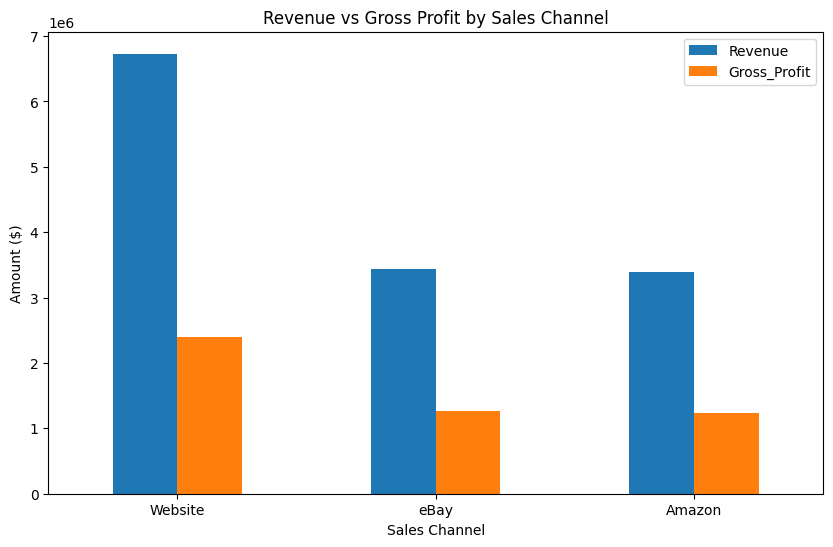

In [92]:
channel_performance[["Revenue", "Gross_Profit"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Revenue vs Gross Profit by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.show()

**Product Category Performance**

In [93]:
category_performance = (
    sales_eda
    .groupby("Category")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

category_performance["Profit Margin"] = (
    category_performance["Gross_Profit"]
    / category_performance["Revenue"]
)

category_performance = category_performance.sort_values(
    "Revenue",
    ascending=False
)

category_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Category,,,,,
Home Office,10842,2.996933e+06,1.091540e+06,19557,0.364219
Lifestyle Products,8004,2.695107e+06,1.002497e+06,14771,0.371970
Technology Accessories,8837,2.144993e+06,7.076018e+05,15899,0.329885
Storage & Organisation,8615,2.094157e+06,7.869053e+05,15680,0.375762
Lighting,6607,1.876333e+06,6.786723e+05,12087,0.361701
Desk Accessories,7090,1.746284e+06,6.326440e+05,12716,0.362280


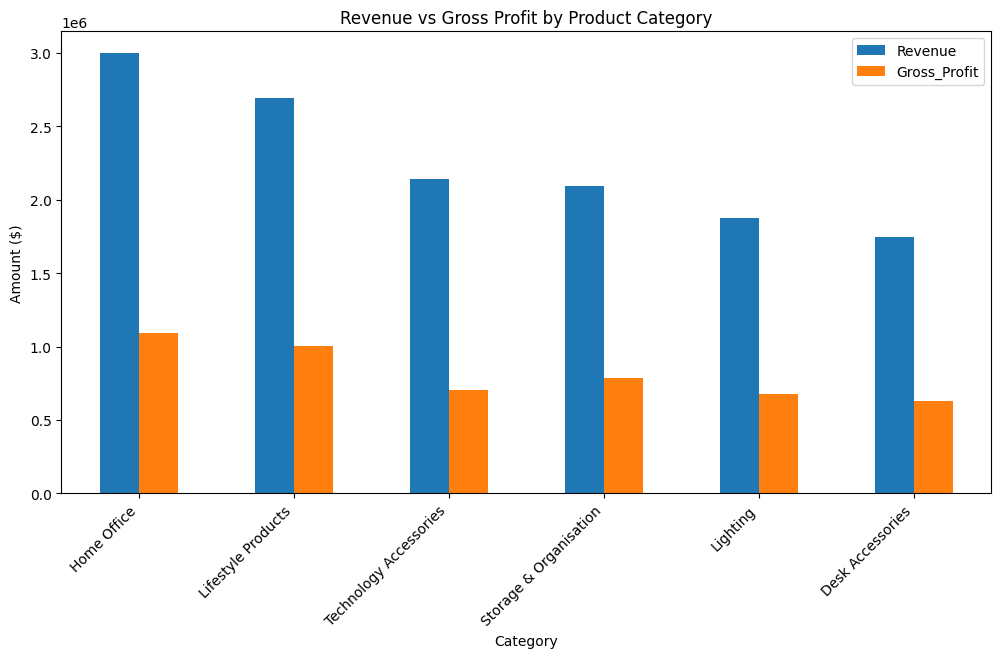

In [94]:
category_performance[["Revenue", "Gross_Profit"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Revenue vs Gross Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=45, ha="right")
plt.show()

**Individual Product Performance**

In [95]:
product_performance = (
    sales_eda
    .groupby(["Product ID", "Product Name", "Category"])
    .agg(
        Transactions=("Order ID", "count"),
        Quantity=("Quantity", "sum"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
)

product_performance["Profit Margin"] = (
    product_performance["Gross_Profit"]
    / product_performance["Revenue"]
)

**Top product by Revenue**

In [96]:
top_revenue_products = (
    product_performance
    .sort_values("Revenue", ascending=False)
    .head(10)
)

top_revenue_products

,,,Transactions,Quantity,Revenue,Gross_Profit,Profit Margin
Product ID,Product Name,Category,,,,,
P1161,Smart Planner 09,Lifestyle Products,1125,2058,574695.3240,217265.8840,0.378054
P1108,Classic Drawer Unit 16,Storage & Organisation,927,1681,412926.6120,180012.5520,0.435943
P1174,Compact Aroma Diffuser 22,Lifestyle Products,672,1258,325265.1650,100096.6350,0.307739
P1004,Minimal Desk Mat 04,Home Office,634,1164,308034.1980,137169.2480,0.445305
P1179,Adjustable Backpack 27,Lifestyle Products,548,1030,277569.1950,125616.8250,0.452560
P1072,Ergonomic Task Light 08,Lighting,494,903,268889.1020,108872.2020,0.404896
P1033,Smart Mouse Pad 01,Desk Accessories,681,1248,253082.5710,97729.6910,0.386157
P1101,Modern Storage Box 09,Storage & Organisation,454,797,233139.3865,113652.3665,0.487487
P1173,Premium Backpack 21,Lifestyle Products,401,741,203645.2620,91944.7420,0.451495


**Top product by profit**

In [97]:
top_profit_products = (
    product_performance
    .sort_values("Gross_Profit", ascending=False)
    .head(10)
)

top_profit_products

,,,Transactions,Quantity,Revenue,Gross_Profit,Profit Margin
Product ID,Product Name,Category,,,,,
P1161,Smart Planner 09,Lifestyle Products,1125,2058,574695.3240,217265.8840,0.378054
P1108,Classic Drawer Unit 16,Storage & Organisation,927,1681,412926.6120,180012.5520,0.435943
P1004,Minimal Desk Mat 04,Home Office,634,1164,308034.1980,137169.2480,0.445305
P1179,Adjustable Backpack 27,Lifestyle Products,548,1030,277569.1950,125616.8250,0.452560
P1101,Modern Storage Box 09,Storage & Organisation,454,797,233139.3865,113652.3665,0.487487
P1072,Ergonomic Task Light 08,Lighting,494,903,268889.1020,108872.2020,0.404896
P1174,Compact Aroma Diffuser 22,Lifestyle Products,672,1258,325265.1650,100096.6350,0.307739
P1033,Smart Mouse Pad 01,Desk Accessories,681,1248,253082.5710,97729.6910,0.386157
P1173,Premium Backpack 21,Lifestyle Products,401,741,203645.2620,91944.7420,0.451495


**Performance gaps**

In [98]:
product_comparison = (
    product_performance
    .sort_values("Revenue", ascending=False)
)

product_comparison[
    ["Revenue", "Gross_Profit", "Profit Margin"]
].head(20)

,,,Revenue,Gross_Profit,Profit Margin
Product ID,Product Name,Category,,,
P1161,Smart Planner 09,Lifestyle Products,574695.3240,217265.8840,0.378054
P1108,Classic Drawer Unit 16,Storage & Organisation,412926.6120,180012.5520,0.435943
P1174,Compact Aroma Diffuser 22,Lifestyle Products,325265.1650,100096.6350,0.307739
P1004,Minimal Desk Mat 04,Home Office,308034.1980,137169.2480,0.445305
P1179,Adjustable Backpack 27,Lifestyle Products,277569.1950,125616.8250,0.452560
P1072,Ergonomic Task Light 08,Lighting,268889.1020,108872.2020,0.404896
P1033,Smart Mouse Pad 01,Desk Accessories,253082.5710,97729.6910,0.386157
P1101,Modern Storage Box 09,Storage & Organisation,233139.3865,113652.3665,0.487487
P1173,Premium Backpack 21,Lifestyle Products,203645.2620,91944.7420,0.451495


In [99]:
# Merge customer information into sales data
sales_customer = sales_eda.merge(
    customers[[
        "Customer ID",
        "Customer Segment"
    ]],
    on="Customer ID",
    how="left",
    validate="many_to_one"
)

# Treat missing Customer IDs as Unknown Customer
sales_customer["Customer Segment"] = (
    sales_customer["Customer Segment"]
    .fillna("Unknown Customer")
)

sales_customer.head()

,Order ID,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel,State,Shipping Cost,Return Status,...,Category,Unit Cost,Selling Price,Gross Sales,Discount Amount,Net Revenue,COGS,Gross Profit,Profit Margin,Customer Segment
0,O000115,C02782,P1103,3,11.41,0.0,Amazon,Victoria,17.66,Completed,...,Storage & Organisation,7.44,11.41,34.23,0.0,34.23,22.32,-5.75,-0.167981,Student
1,O000376,C07071,P1103,1,11.41,0.0,Amazon,Queensland,8.99,Completed,...,Storage & Organisation,7.44,11.41,11.41,0.0,11.41,7.44,-5.02,-0.439965,Student
2,O000521,C01655,P1103,3,11.41,0.0,Website,Victoria,20.12,Completed,...,Storage & Organisation,7.44,11.41,34.23,0.0,34.23,22.32,-8.21,-0.239848,Professional
3,O000544,C04717,P1103,4,11.41,0.0,Amazon,Queensland,41.37,Completed,...,Storage & Organisation,7.44,11.41,45.64,0.0,45.64,29.76,-25.49,-0.558501,Individual
4,O000580,C00724,P1103,3,11.41,0.0,Website,South Australia,22.43,Completed,...,Storage & Organisation,7.44,11.41,34.23,0.0,34.23,22.32,-10.52,-0.307333,Individual


**Customer Segment Performance**

Business question: Which customer segments contribute the most revenue and gross profit, and are some segments more profitable than others?

In [100]:
customer_segment_performance = (
    sales_customer
    .groupby("Customer Segment")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

customer_segment_performance["Profit Margin"] = (
    customer_segment_performance["Gross_Profit"]
    / customer_segment_performance["Revenue"]
)

customer_segment_performance = (
    customer_segment_performance
    .sort_values("Revenue", ascending=False)
)

customer_segment_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Customer Segment,,,,,
Individual,21304,5.804756e+06,2.097759e+06,38536,0.361386
Student,10320,2.815665e+06,1.018297e+06,18859,0.361654
Professional,9344,2.502088e+06,9.024081e+05,17045,0.360662
Small Business,8887,2.389829e+06,8.655050e+05,16015,0.362162
Unknown Customer,140,4.146929e+04,1.589171e+04,255,0.383216


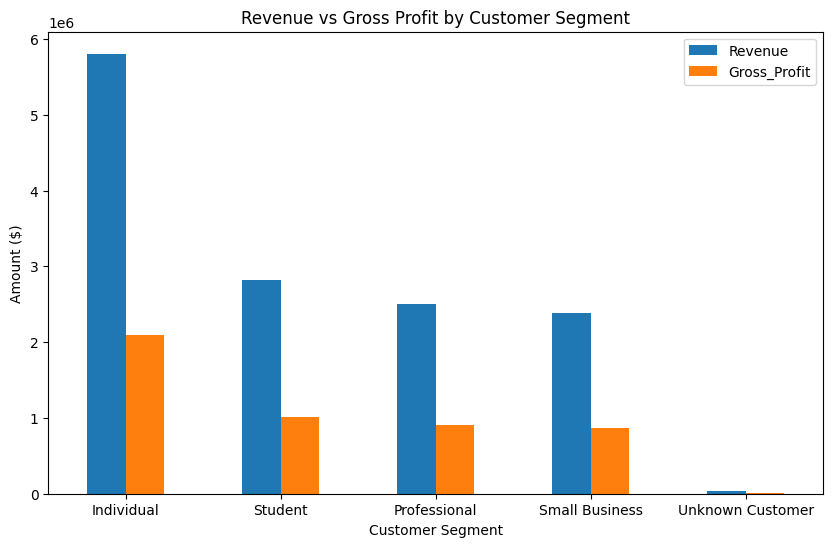

In [101]:
customer_segment_performance[
    ["Revenue", "Gross_Profit"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Revenue vs Gross Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.show()

Profit Margin by Customer Segment

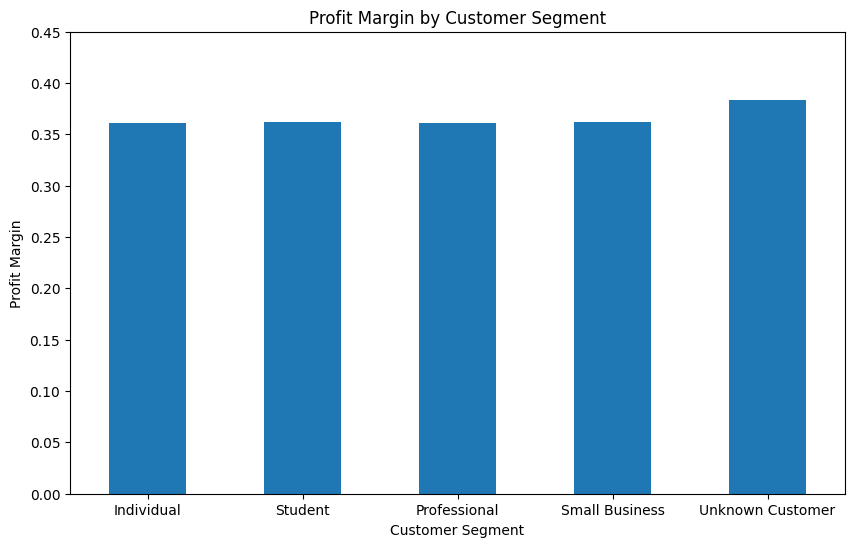

In [102]:

customer_segment_performance["Profit Margin"].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Profit Margin by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit Margin")
plt.xticks(rotation=0)
plt.ylim(0, 0.45)
plt.show()

Business Interpretation - Customer Segment

Customer segment performance is primarily driven by revenue scale rather than differences in profitability. Individual customers are the largest contributor to both revenue and gross profit, while the known customer segments maintain very similar profit margins of approximately 36%. This suggests that customer segment is not a major differentiator of profitability for Harbour & Co., although Individual customers represent the largest opportunity for profitable growth due to their higher revenue contribution.

**State Performance**

Business question: Which states generate the most revenue and gross profit, and are there meaningful differences in profitability across geographic markets?

In [103]:
state_performance = (
    sales_eda
    .groupby("State")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

state_performance["Profit Margin"] = (
    state_performance["Gross_Profit"]
    / state_performance["Revenue"]
)

state_performance = (
    state_performance
    .sort_values("Revenue", ascending=False)
)

state_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
State,,,,,
New South Wales,14992,4.108518e+06,1.509700e+06,27453,0.367456
Victoria,13671,3.666501e+06,1.379776e+06,24545,0.376319
Queensland,11108,3.031062e+06,1.075389e+06,20298,0.354790
Western Australia,4767,1.269358e+06,4.123332e+05,8499,0.324836
South Australia,2937,8.003957e+05,2.891760e+05,5323,0.361291
Tasmania,1126,3.176313e+05,1.088478e+05,2103,0.342686
Australian Capital Territory,924,2.515174e+05,9.423565e+04,1692,0.374669
Northern Territory,470,1.088235e+05,3.040426e+04,797,0.279391


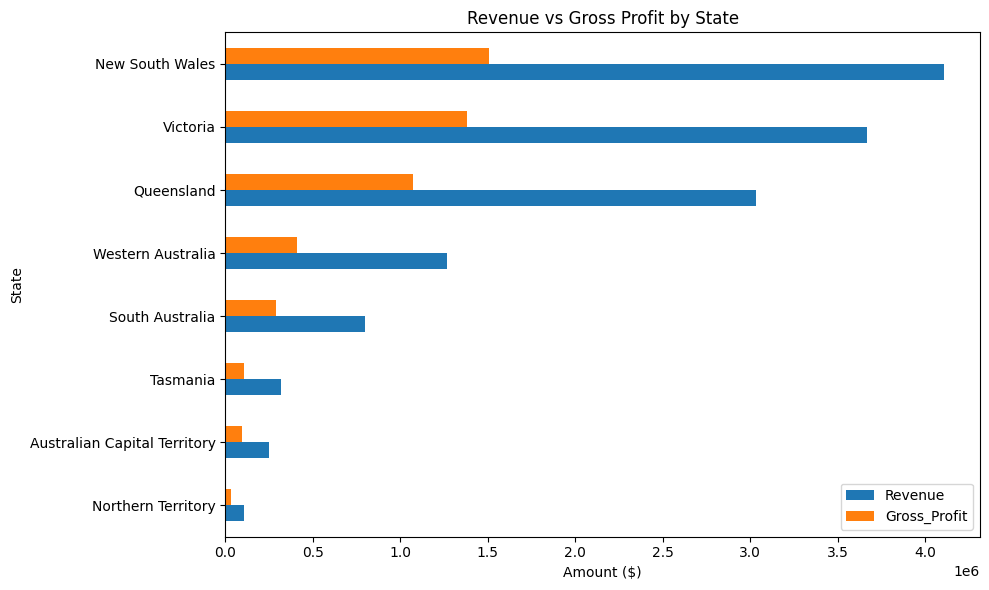

In [104]:
# Revenue vs Profit by state

state_performance[
    ["Revenue", "Gross_Profit"]
].sort_values("Revenue").plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Revenue vs Gross Profit by State")
plt.xlabel("Amount ($)")
plt.ylabel("State")
plt.legend(title="")
plt.tight_layout()
plt.show()

Profit margin by State

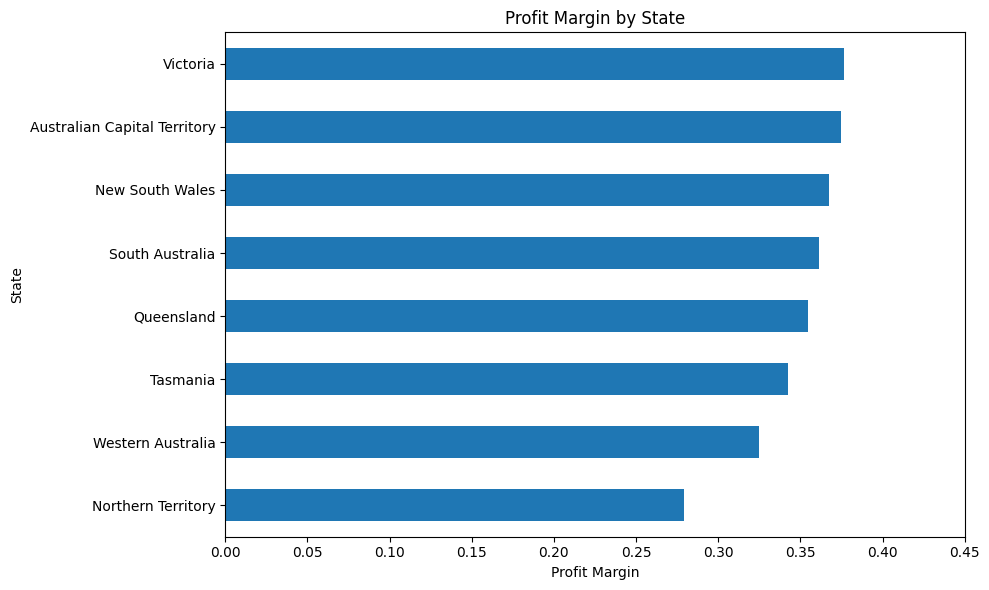

In [105]:
state_performance["Profit Margin"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Profit Margin by State")
plt.xlabel("Profit Margin")
plt.ylabel("State")
plt.xlim(0, 0.45)
plt.tight_layout()
plt.show()

**Business Interpretation - State**

Geographic performance shows that Harbour & Co.'s revenue is highly concentrated in New South Wales, Victoria and Queensland, with these three states accounting for approximately 80% of total revenue. Victoria is particularly attractive because it combines substantial revenue contribution with the highest profit margin among the major markets. In contrast, Western Australia generates meaningful revenue but has a comparatively lower profit margin, suggesting a potential opportunity to investigate the drivers of lower profitability. Smaller markets such as the Northern Territory should be interpreted cautiously because their transaction volumes are relatively low.

**Return Analysis**

This includes 4 sub-sections (Overall Returns, Returns by Sales Channel, Returns by Product Category, Returns by State)

Business question: How significant are product returns for Harbour & Co., and how are returns distributed across sales channels, product categories and states?

**1. Overall Returns**

In [106]:
# Overall return performance

return_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Returned Transactions",
        "Return Rate",
        "Returned Quantity"
    ],
    "Value": [
        len(sales_eda),
        (sales_eda["Return Status"] == "Returned").sum(),
        (sales_eda["Return Status"] == "Returned").mean(),
        sales_eda.loc[
            sales_eda["Return Status"] == "Returned",
            "Quantity"
        ].abs().sum()
    ]
})

return_summary

,Metric,Value
0,Total Transactions,49995.000000
1,Returned Transactions,906.000000
2,Return Rate,0.018122
3,Returned Quantity,1724.000000


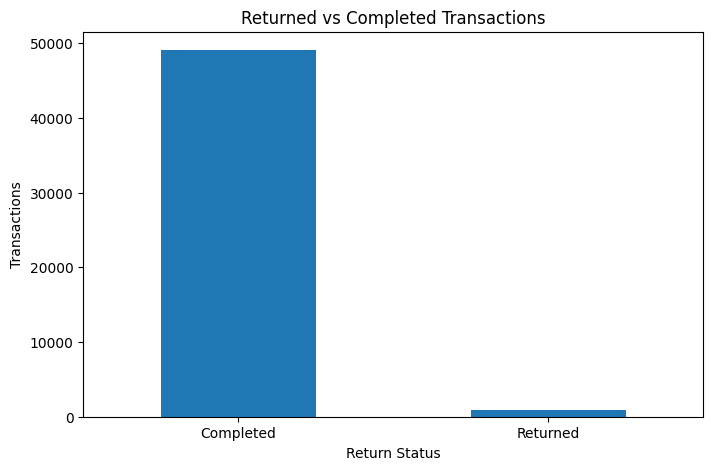

In [107]:
return_counts = (
    sales_eda["Return Status"]
    .value_counts()
)

return_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Returned vs Completed Transactions")
plt.xlabel("Return Status")
plt.ylabel("Transactions")
plt.xticks(rotation=0)
plt.show()

**2. Returns by Sales Channel**

Which sales channels have the highest return activity?

In [108]:
return_channel = (
    sales_eda
    .groupby("Sales Channel")
    .agg(
        Transactions=("Order ID", "count"),
        Returned_Transactions=(
            "Return Status",
            lambda x: (x == "Returned").sum()
        ),
        Quantity=("Quantity", "sum")
    )
)

return_channel["Return Rate"] = (
    return_channel["Returned_Transactions"]
    / return_channel["Transactions"]
)

return_channel = return_channel.sort_values(
    "Return Rate",
    ascending=False
)

return_channel

,Transactions,Returned_Transactions,Quantity,Return Rate
Sales Channel,,,,
Amazon,12480,242,22484,0.019391
Website,25024,454,45328,0.018143
eBay,12491,210,22898,0.016812


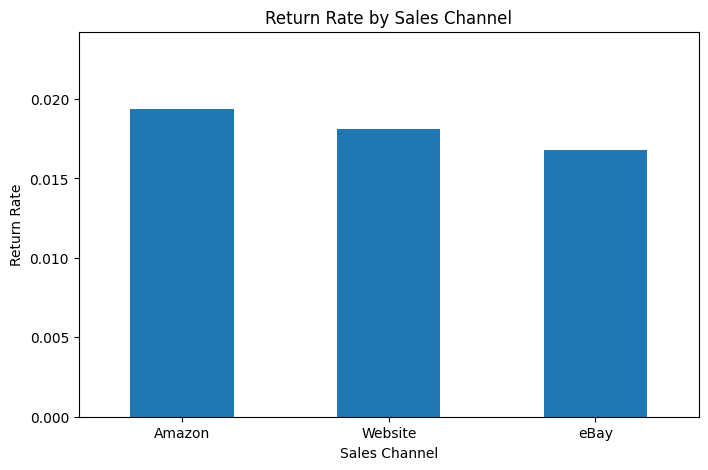

In [109]:
return_channel["Return Rate"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Return Rate by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Return Rate")
plt.ylim(0, return_channel["Return Rate"].max() * 1.25)
plt.xticks(rotation=0)
plt.show()

**Findings - Sales Channels**

Return rates are relatively consistent across all three sales channels, ranging from 1.68% to 1.94%. Amazon has the highest return rate, while eBay has the lowest, but the difference is relatively small. This suggests that sales channel is not a major driver of return behaviour.

**3. Returns by Product Category**

Are returns concentrated in particular product categories?

In [110]:
return_category = (
    sales_eda
    .groupby("Category")
    .agg(
        Transactions=("Order ID", "count"),
        Returned_Transactions=(
            "Return Status",
            lambda x: (x == "Returned").sum()
        ),
        Quantity=("Quantity", "sum")
    )
)

return_category["Return Rate"] = (
    return_category["Returned_Transactions"]
    / return_category["Transactions"]
)

return_category = return_category.sort_values(
    "Return Rate",
    ascending=False
)

return_category

,Transactions,Returned_Transactions,Quantity,Return Rate
Category,,,,
Technology Accessories,8837,175,15899,0.019803
Home Office,10842,208,19557,0.019185
Desk Accessories,7090,134,12716,0.018900
Lighting,6607,113,12087,0.017103
Lifestyle Products,8004,133,14771,0.016617
Storage & Organisation,8615,143,15680,0.016599


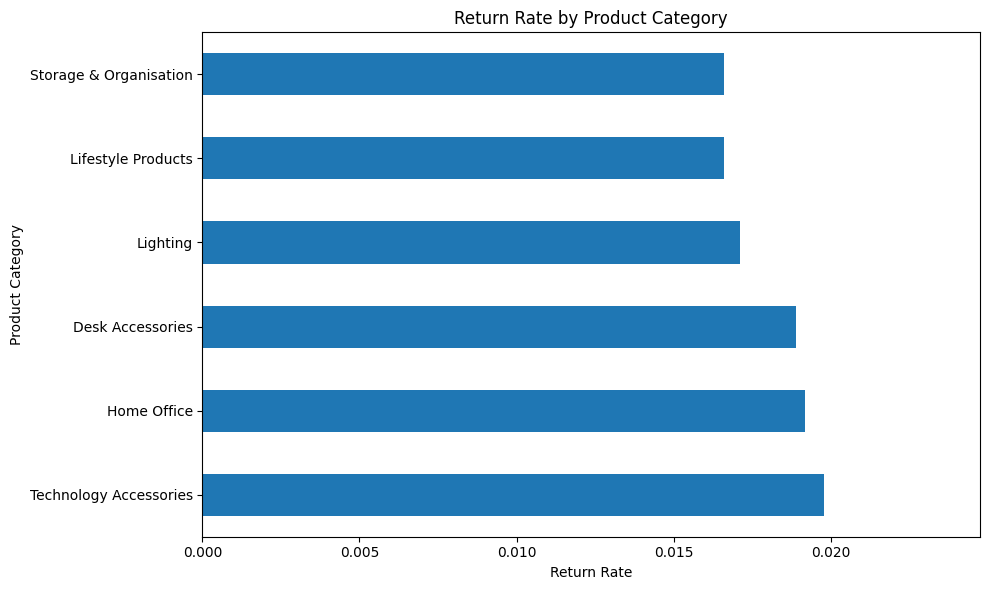

In [111]:
return_category["Return Rate"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Return Rate by Product Category")
plt.xlabel("Return Rate")
plt.ylabel("Product Category")
plt.xlim(0, return_category["Return Rate"].max() * 1.25)
plt.tight_layout()
plt.show()

**Findings - Product Category**

Return rates are relatively consistent across product categories, ranging from 1.66% to 1.98%. Technology Accessories has the highest return rate, while Lifestyle Products and Storage & Organisation have the lowest. However, the relatively small difference between categories suggests that product category is not a major differentiator of return behaviour.

**Returns by State**

Are returns concentrated in particular geographic markets?

In [112]:
return_state = (
    sales_eda
    .groupby("State")
    .agg(
        Transactions=("Order ID", "count"),
        Returned_Transactions=(
            "Return Status",
            lambda x: (x == "Returned").sum()
        ),
        Quantity=("Quantity", "sum")
    )
)

return_state["Return Rate"] = (
    return_state["Returned_Transactions"]
    / return_state["Transactions"]
)

return_state = return_state.sort_values(
    "Return Rate",
    ascending=False
)

return_state

,Transactions,Returned_Transactions,Quantity,Return Rate
State,,,,
Northern Territory,470,12,797,0.025532
Tasmania,1126,24,2103,0.021314
South Australia,2937,58,5323,0.019748
Victoria,13671,254,24545,0.018579
New South Wales,14992,274,27453,0.018276
Western Australia,4767,85,8499,0.017831
Queensland,11108,185,20298,0.016655
Australian Capital Territory,924,14,1692,0.015152


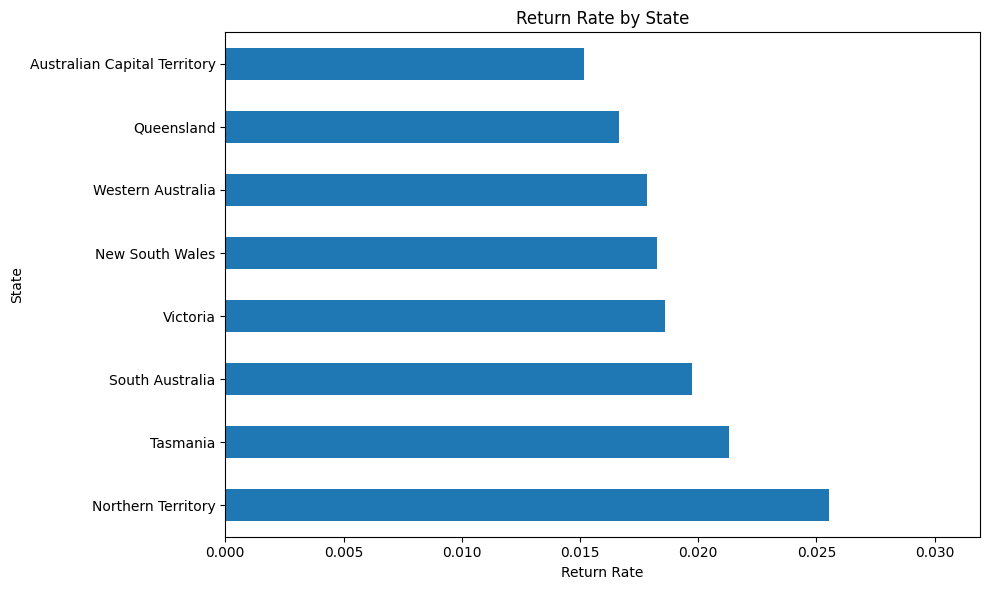

In [113]:
return_state["Return Rate"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Return Rate by State")
plt.xlabel("Return Rate")
plt.ylabel("State")
plt.xlim(0, return_state["Return Rate"].max() * 1.25)
plt.tight_layout()
plt.show()

**Conclusion (Business Interpretation) - Returns Analysis**

Returns do not appear to be a major business-wide issue based on transaction frequency. Return rates remain relatively consistent across sales channels and product categories, while higher rates in smaller geographic markets should be interpreted cautiously due to their lower transaction volumes. Among the major markets, return rates are relatively stable, suggesting that returns are not strongly concentrated in any particular channel, category or large geographic market.

**Discounts & Campaigns**

This includes 4 sub-sections (Discount Performance, Campaign vs No Campaign, Campaign Performance, Campaign x Channel)

Business question: How do discounts and marketing campaigns affect revenue and profitability?

**1. Discount Peformance**

In [114]:
sales_eda["Discount Band"] = pd.cut(
    sales_eda["Discount"],
    bins=[-0.001, 0, 0.05, 0.10, 0.20, 1],
    labels=[
        "No Discount",
        "1-5%",
        "6-10%",
        "11-20%",
        "20%+"
    ]
)

sales_eda["Discount Band"].value_counts().sort_index()

,count
Discount Band,
No Discount,39031
1-5%,930
6-10%,5576
11-20%,4458
20%+,0


In [115]:
discount_performance = (
    sales_eda
    .groupby("Discount Band", observed=True)
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

discount_performance["Profit Margin"] = (
    discount_performance["Gross_Profit"]
    / discount_performance["Revenue"]
)

discount_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Discount Band,,,,,
No Discount,39031,1.087383e+07,4.111236e+06,71072,0.378085
1-5%,930,2.518376e+05,8.866036e+04,1672,0.352054
6-10%,5576,1.415395e+06,4.398107e+05,10069,0.310734
11-20%,4458,1.012740e+06,2.601539e+05,7897,0.256881


Profit margin by Discount Band

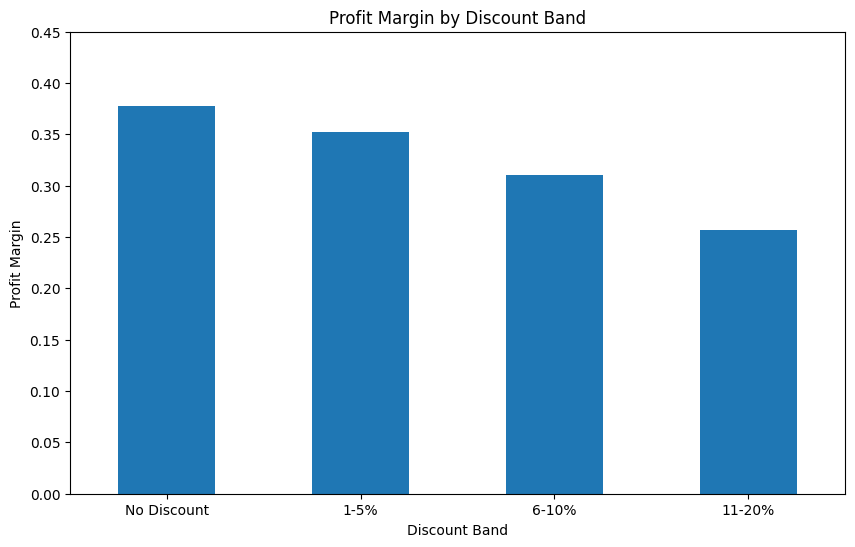

In [116]:
discount_performance["Profit Margin"].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin")
plt.ylim(0, 0.45)
plt.xticks(rotation=0)
plt.show()

**Findings - Discount Band**

Higher discount levels are associated with lower profit margins. Profit margin declines from 37.81% for transactions without discounts to 25.69% for transactions receiving discounts of 11–20%. This suggests that deeper discounting may reduce profitability and should be carefully evaluated against the additional sales generated.

**2. Campaigns vs No Campaign**

Do campaigns actually generate more profitable sales than transactions without campaigns?

In [117]:
sales_eda["Campaign Status"] = sales_eda["Campaign ID"].notna().map({
    True: "Campaign",
    False: "No Campaign"
})

campaign_status_performance = (
    sales_eda
    .groupby("Campaign Status")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

campaign_status_performance["Profit Margin"] = (
    campaign_status_performance["Gross_Profit"]
    / campaign_status_performance["Revenue"]
)

campaign_status_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Campaign Status,,,,,
Campaign,8118,1.954966e+06,5.623019e+05,14480,0.287627
No Campaign,41877,1.159884e+07,4.337559e+06,76230,0.373965


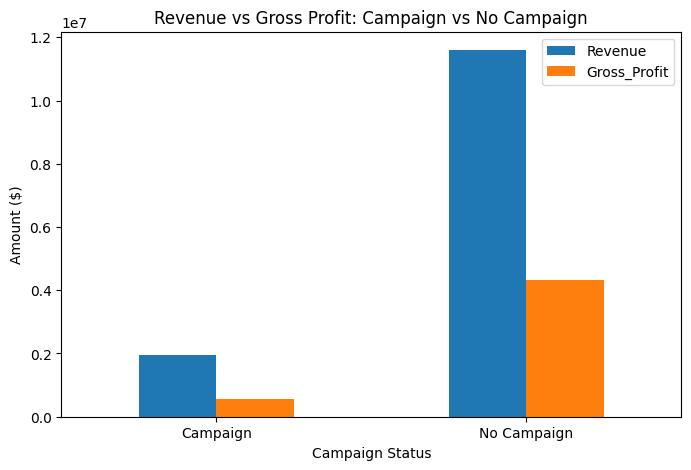

In [118]:
campaign_status_performance[
    ["Revenue", "Gross_Profit"]
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Revenue vs Gross Profit: Campaign vs No Campaign")
plt.xlabel("Campaign Status")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.show()

Profit margin by campaign vs no campaign

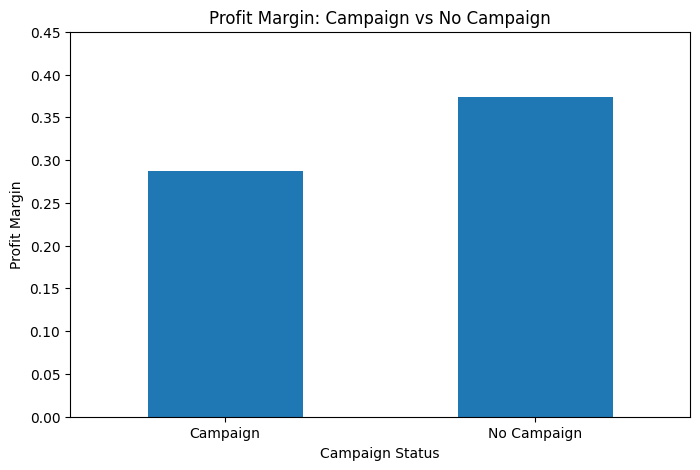

In [119]:
campaign_status_performance["Profit Margin"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Profit Margin: Campaign vs No Campaign")
plt.xlabel("Campaign Status")
plt.ylabel("Profit Margin")
plt.ylim(0, 0.45)
plt.xticks(rotation=0)
plt.show()

**Findings - Campaign vs No Campaign**

Transactions associated with campaigns generate a substantially lower profit margin than transactions without campaigns, with margins of 28.76% and 37.40%, respectively. This 8.64 percentage-point difference suggests that campaign activity may be associated with lower profitability. However, the result does not establish causation, as campaign transactions may differ in discount levels, products, channels or other characteristics. Further campaign-level analysis is required to determine which campaigns generate profitable growth.

**Campaign Performance**

In [120]:
sales_campaign = sales_eda.merge(
    campaigns,
    on="Campaign ID",
    how="left",
    validate="many_to_one"
)

sales_campaign.head()

,Order ID,Customer ID,Product ID,Quantity,Unit Price,Discount,Sales Channel_x,State,Shipping Cost,Return Status,...,Gross Profit,Profit Margin,Discount Band,Campaign Status,Campaign Name,Start Date,End Date,Promotion Type,Discount Rate,Sales Channel_y
0,O000115,C02782,P1103,3,11.41,0.0,Amazon,Victoria,17.66,Completed,...,-5.75,-0.167981,No Discount,No Campaign,NaN,NaN,NaN,NaN,NaN,NaN
1,O000376,C07071,P1103,1,11.41,0.0,Amazon,Queensland,8.99,Completed,...,-5.02,-0.439965,No Discount,No Campaign,NaN,NaN,NaN,NaN,NaN,NaN
2,O000521,C01655,P1103,3,11.41,0.0,Website,Victoria,20.12,Completed,...,-8.21,-0.239848,No Discount,No Campaign,NaN,NaN,NaN,NaN,NaN,NaN
3,O000544,C04717,P1103,4,11.41,0.0,Amazon,Queensland,41.37,Completed,...,-25.49,-0.558501,No Discount,No Campaign,NaN,NaN,NaN,NaN,NaN,NaN
4,O000580,C00724,P1103,3,11.41,0.0,Website,South Australia,22.43,Completed,...,-10.52,-0.307333,No Discount,No Campaign,NaN,NaN,NaN,NaN,NaN,NaN


In [121]:
sales_campaign["Campaign ID"].notna().sum()

np.int64(8118)

In [122]:
campaign_performance = (
    sales_campaign[sales_campaign["Campaign ID"].notna()]
    .groupby("Campaign ID")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

campaign_performance["Profit Margin"] = (
    campaign_performance["Gross_Profit"]
    / campaign_performance["Revenue"]
)

campaign_performance = campaign_performance.sort_values(
    "Gross_Profit",
    ascending=False
)

campaign_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Campaign ID,,,,,
CMP004,824,215540.0100,69135.4900,1486,0.320755
CMP001,816,211562.7390,65585.0290,1486,0.310003
CMP008,846,208857.0780,64244.0680,1493,0.307598
CMP011,814,205995.4380,63205.5030,1498,0.306830
CMP014,670,167351.7420,52587.3520,1189,0.314232
CMP002,857,192572.3620,51570.8520,1466,0.267800
CMP009,881,189151.4010,49371.3610,1545,0.261015
CMP007,606,152510.8500,46436.4500,1099,0.304480
CMP005,365,92665.2150,25568.1350,671,0.275919


In [123]:
# enrich table with campaign name / campaign attributes

campaign_lookup = campaigns[
    ["Campaign ID", "Campaign Name", "Sales Channel"]
]

campaign_performance_named = (
    campaign_performance
    .reset_index()
    .merge(
        campaign_lookup,
        on="Campaign ID",
        how="left"
    )
)

campaign_performance_named

,Campaign ID,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin,Campaign Name,Sales Channel
0,CMP004,824,215540.0100,69135.4900,1486,0.320755,Winter Essentials,Website
1,CMP001,816,211562.7390,65585.0290,1486,0.310003,New Year Refresh,Website
2,CMP008,846,208857.0780,64244.0680,1493,0.307598,New Year Refresh,Website
3,CMP011,814,205995.4380,63205.5030,1498,0.306830,Winter Essentials,Website
4,CMP014,670,167351.7420,52587.3520,1189,0.314232,Holiday Sale,Website
5,CMP002,857,192572.3620,51570.8520,1466,0.267800,Autumn Workspace,Website
6,CMP009,881,189151.4010,49371.3610,1545,0.261015,Autumn Workspace,Website
7,CMP007,606,152510.8500,46436.4500,1099,0.304480,Holiday Sale,Website
8,CMP005,365,92665.2150,25568.1350,671,0.275919,Spring Workspace,Amazon
9,CMP012,406,88789.7335,23238.8435,672,0.261729,Spring Workspace,Amazon


In [124]:
campaigns.columns

Index(['Campaign ID', 'Campaign Name', 'Start Date', 'End Date',
       'Promotion Type', 'Discount Rate', 'Sales Channel'],
      dtype='object')

**Findings - Campaign Performance**

Campaign profitability varies considerably across campaigns. Winter Essentials, New Year Refresh and Holiday Sale campaigns generally achieve higher profit margins, while Mid-Year Marketplace and Black Friday campaigns show lower margins. This indicates that campaign performance should be evaluated based on profitability rather than revenue alone. Further analysis of promotion type, discount rate and sales channel is required to identify factors associated with these differences.

**4. Campaign x Channel**

In [125]:
campaign_details = campaigns[
    [
        "Campaign ID",
        "Campaign Name",
        "Promotion Type",
        "Discount Rate",
        "Sales Channel"
    ]
].copy()

campaign_details

,Campaign ID,Campaign Name,Promotion Type,Discount Rate,Sales Channel
0,CMP001,New Year Refresh,Percentage Discount,0.10,Website
1,CMP002,Autumn Workspace,Percentage Discount,0.15,Website
2,CMP003,Mid-Year Marketplace,Percentage Discount,0.20,eBay
3,CMP004,Winter Essentials,Percentage Discount,0.10,Website
4,CMP005,Spring Workspace,Percentage Discount,0.15,Amazon
5,CMP006,Black Friday,Percentage Discount,0.20,Amazon
6,CMP007,Holiday Sale,Percentage Discount,0.10,Website
7,CMP008,New Year Refresh,Percentage Discount,0.10,Website
8,CMP009,Autumn Workspace,Percentage Discount,0.15,Website
9,CMP010,Mid-Year Marketplace,Percentage Discount,0.20,eBay


In [126]:
campaign_discount_performance = (
    sales_campaign[sales_campaign["Campaign ID"].notna()]
    .groupby("Discount Rate")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

campaign_discount_performance["Profit Margin"] = (
    campaign_discount_performance["Gross_Profit"]
    / campaign_discount_performance["Revenue"]
)

campaign_discount_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Discount Rate,,,,,
0.10,4576,1.161818e+06,361193.8920,8251,0.310887
0.15,2509,5.631787e+05,149749.1915,4354,0.265900
0.20,1033,2.299695e+05,51358.7860,1875,0.223329


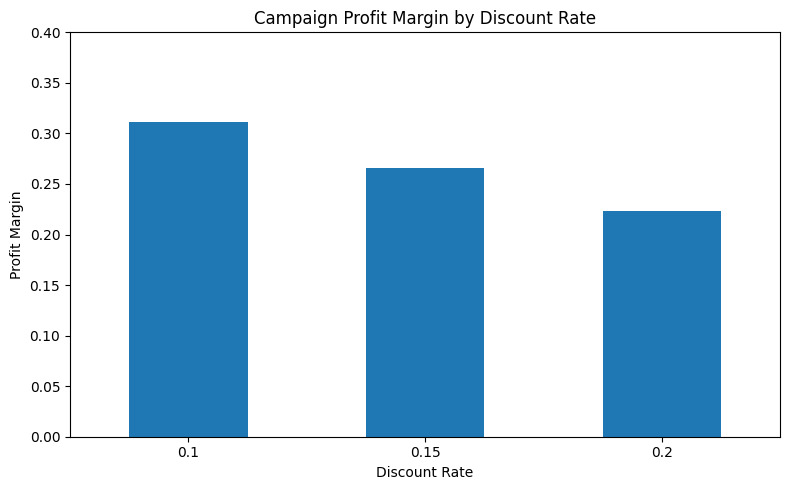

In [127]:
campaign_discount_performance["Profit Margin"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Campaign Profit Margin by Discount Rate")
plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin")
plt.ylim(0, 0.40)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Conclusion - Discounts and Campaigns**

Campaigns with higher discount rates are consistently associated with lower profit margins. Campaign margin declines from 31.09% at a 10% discount to 22.33% at a 20% discount, an 8.76 percentage-point difference. This reinforces the broader finding that deeper discounting is associated with lower profitability, although the relationship should not be interpreted as causal because discount rates are not independent of sales channel in the campaign data.

**Time Trends**

This includes 3 sub-sections (Monthly Revenue & Gross Profit, Monthly Profit Margin, Monthly Transactions / Qantity)

**1. Monthly Revenue & Gross Profit**

In [128]:
monthly_performance = (
    sales_eda
    .set_index("Order Date")
    .resample("ME")
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

monthly_performance["Profit Margin"] = (
    monthly_performance["Gross_Profit"]
    / monthly_performance["Revenue"]
)

monthly_performance

,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
Order Date,,,,,
2024-01-31,2069,565731.7665,199056.7465,3801,0.351857
2024-02-29,1936,552945.1285,208933.6985,3594,0.377856
2024-03-31,2179,561511.3445,196508.3195,3871,0.349963
2024-04-30,2048,532324.9035,190193.0335,3635,0.357287
2024-05-31,2078,567331.3850,212267.7750,3824,0.374151
2024-06-30,2028,546972.3055,192334.0755,3606,0.351634
2024-07-31,2159,584885.4120,209346.5020,3901,0.357927
2024-08-31,2153,597477.7525,222151.9075,3958,0.371816
2024-09-30,2048,568443.8370,202528.8770,3803,0.356287


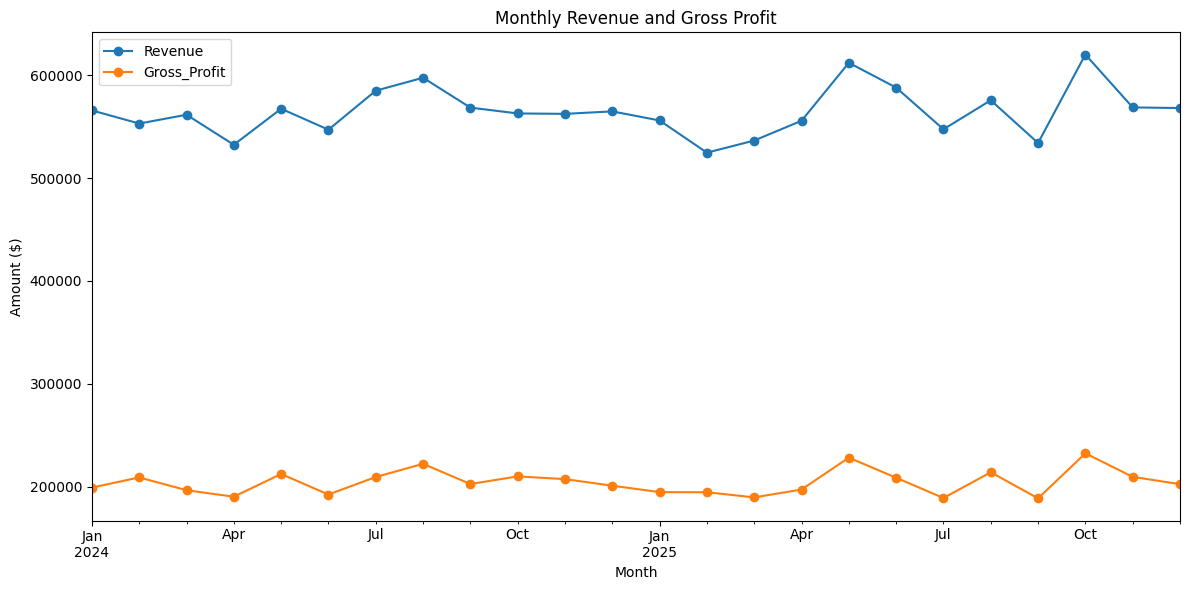

In [129]:
monthly_performance[["Revenue", "Gross_Profit"]].plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Monthly Revenue and Gross Profit")
plt.xlabel("Month")
plt.ylabel("Amount ($)")
plt.legend()
plt.tight_layout()
plt.show()

**2. Monthly Profit Margin**

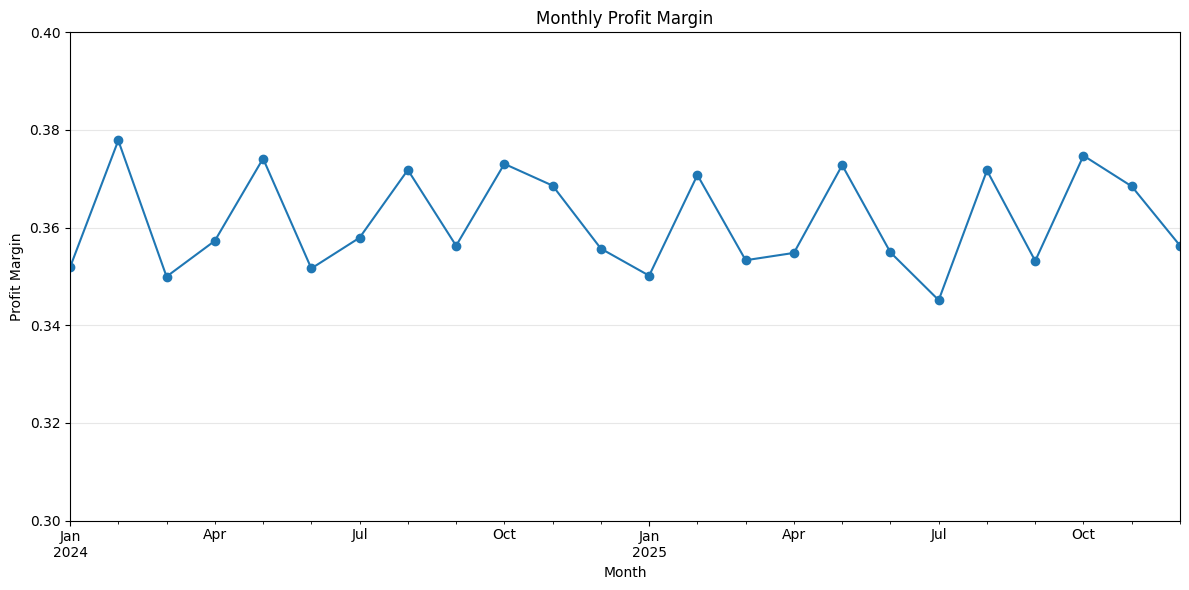

In [130]:
# Monthly profit margin

monthly_performance["Profit Margin"].plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Monthly Profit Margin")
plt.xlabel("Month")
plt.ylabel("Profit Margin")
plt.ylim(0.30, 0.40)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Findings - Monthly Profit Margin**

Profitability remained relatively stable over time, with monthly profit margins fluctuating between approximately 34.5% and 37.8%. No clear long-term upward or downward trend was observed.

**3. Monthly Transactions**

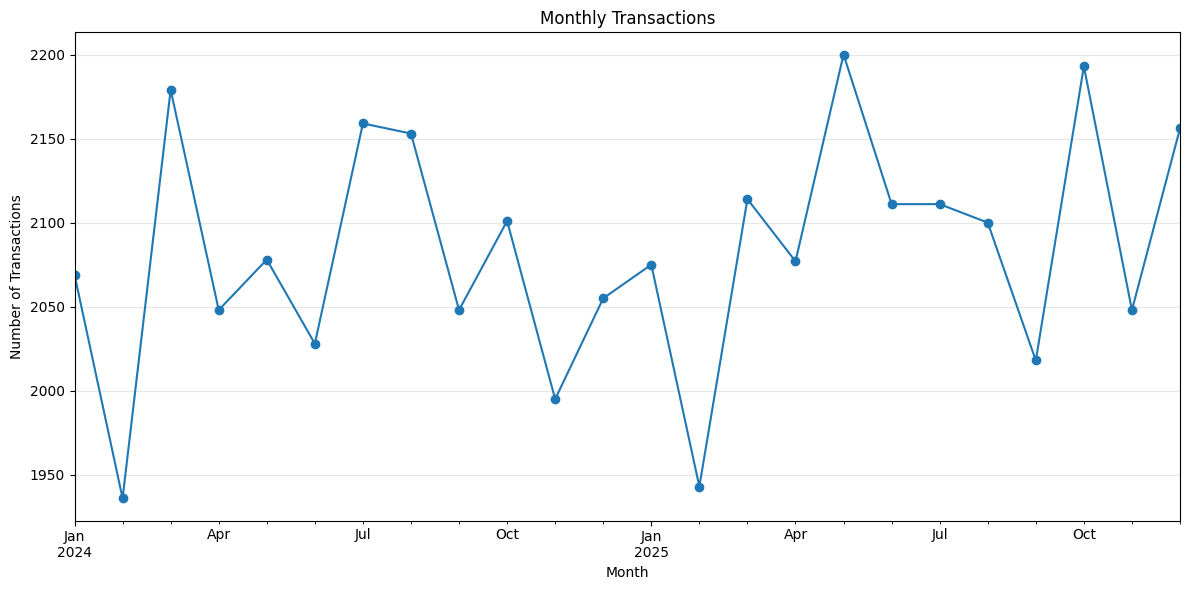

In [131]:
monthly_performance["Transactions"].plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Monthly Transactions")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Business Interpretation - Time Trends**

Harbour & Co.'s overall performance remained relatively stable throughout the observed period. Monthly revenue, transaction volume and profit margin fluctuated within relatively narrow ranges, with no clear long-term growth or decline trend.

**Cross-Analysis**

Business question: What combinations of business factors are driving revenue and profitability?

**1. Sales Channel x Product Category**

In [132]:
channel_category = (
    sales_eda
    .groupby(["Sales Channel", "Category"])
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Net Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

channel_category["Profit Margin"] = (
    channel_category["Gross_Profit"]
    / channel_category["Revenue"]
)

channel_category = channel_category.reset_index()

channel_category.sort_values(
    "Profit Margin",
    ascending=False
)

,Sales Channel,Category,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
4,Amazon,Storage & Organisation,2196,5.239102e+05,200416.8570,3994,0.382540
14,eBay,Lifestyle Products,2004,7.006906e+05,265096.4270,3801,0.378336
16,eBay,Storage & Organisation,2156,5.318189e+05,201085.1775,3983,0.378108
2,Amazon,Lifestyle Products,1983,6.659005e+05,249090.5340,3599,0.374066
1,Amazon,Home Office,2616,7.590386e+05,282877.6980,4817,0.372679
10,Website,Storage & Organisation,4263,1.038428e+06,385403.2160,7703,0.371141
15,eBay,Lighting,1639,4.716774e+05,174102.1810,3045,0.369113
13,eBay,Home Office,2762,7.532284e+05,277673.4140,4946,0.368644
8,Website,Lifestyle Products,4017,1.328515e+06,488310.4810,7371,0.367561
12,eBay,Desk Accessories,1763,4.381698e+05,160872.7920,3183,0.367147


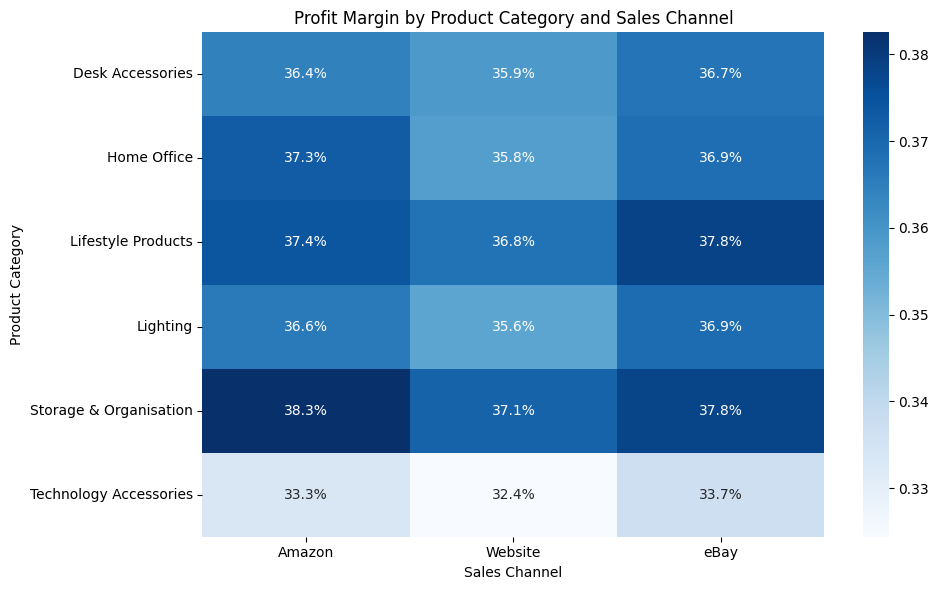

In [133]:
import seaborn as sns

margin_pivot = channel_category.pivot(
    index="Category",
    columns="Sales Channel",
    values="Profit Margin"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    margin_pivot,
    annot=True,
    fmt=".1%",
    cmap="Blues"
)

plt.title("Profit Margin by Product Category and Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

**Findings - Sales Channel x Product Category**

Profitability varies by the combination of sales channel and product category. Technology Accessories consistently records the lowest profit margins across all channels, while Storage & Organisation performs strongly across channels, particularly on Amazon. The Website channel records the lowest profit margin within every product category, suggesting a potential channel-specific profitability issue that warrants further investigation.

**2. Sales Channel x Customer Segment**

In [134]:
# Merge Product Master to get Unit Cost
sales_profit = sales.merge(
    products[["Product ID", "Unit Cost"]],
    on="Product ID",
    how="left"
)

# Calculate Revenue
sales_profit["Revenue"] = (
    sales_profit["Quantity"]
    * sales_profit["Unit Price"]
    * (1 - sales_profit["Discount"])
)

# Calculate Gross Profit
sales_profit["Gross Profit"] = (
    sales_profit["Revenue"]
    - (sales_profit["Quantity"] * sales_profit["Unit Cost"])
    - sales_profit["Shipping Cost"]
)

sales_profit[[
    "Quantity",
    "Unit Price",
    "Discount",
    "Unit Cost",
    "Shipping Cost",
    "Revenue",
    "Gross Profit"
]].head()

,Quantity,Unit Price,Discount,Unit Cost,Shipping Cost,Revenue,Gross Profit
0,3,11.41,0.0,7.44,17.66,34.23,-5.75
1,1,11.41,0.0,7.44,8.99,11.41,-5.02
2,3,11.41,0.0,7.44,20.12,34.23,-8.21
3,4,11.41,0.0,7.44,41.37,45.64,-25.49
4,3,11.41,0.0,7.44,22.43,34.23,-10.52


In [135]:
sales_profit.columns.tolist()

['Order ID',
 'Customer ID',
 'Product ID',
 'Quantity',
 'Unit Price',
 'Discount',
 'Sales Channel',
 'State',
 'Shipping Cost',
 'Return Status',
 'Campaign ID',
 'Shipping Cost Imputed',
 'Order Date',
 'Unit Cost',
 'Revenue',
 'Gross Profit']

In [136]:
sales_customer = (
    sales_profit.merge(
        customers[["Customer ID", "Customer Segment"]],
        on="Customer ID",
        how="left"
    )
)

sales_customer.columns.tolist()

['Order ID',
 'Customer ID',
 'Product ID',
 'Quantity',
 'Unit Price',
 'Discount',
 'Sales Channel',
 'State',
 'Shipping Cost',
 'Return Status',
 'Campaign ID',
 'Shipping Cost Imputed',
 'Order Date',
 'Unit Cost',
 'Revenue',
 'Gross Profit',
 'Customer Segment']

In [137]:
channel_segment = (
    sales_customer
    .groupby(["Sales Channel", "Customer Segment"])
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Revenue", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)

channel_segment["Profit Margin"] = (
    channel_segment["Gross_Profit"]
    / channel_segment["Revenue"]
)

channel_segment

,Sales Channel,Customer Segment,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
0,Amazon,Individual,5334,1.444075e+06,5.265934e+05,9557,0.364658
1,Amazon,Professional,2373,6.500731e+05,2.411291e+05,4273,0.370926
2,Amazon,Small Business,2219,6.100806e+05,2.231210e+05,4022,0.365724
3,Amazon,Student,2525,6.730595e+05,2.459550e+05,4594,0.365428
4,Website,Individual,10650,2.917116e+06,1.043575e+06,19319,0.357742
5,Website,Professional,4614,1.209601e+06,4.282571e+05,8375,0.354048
6,Website,Small Business,4470,1.182323e+06,4.217477e+05,7966,0.356711
7,Website,Student,5215,1.398876e+06,4.961961e+05,9519,0.354710
8,eBay,Individual,5320,1.443565e+06,5.275909e+05,9660,0.365478
9,eBay,Professional,2357,6.424139e+05,2.330219e+05,4397,0.362729


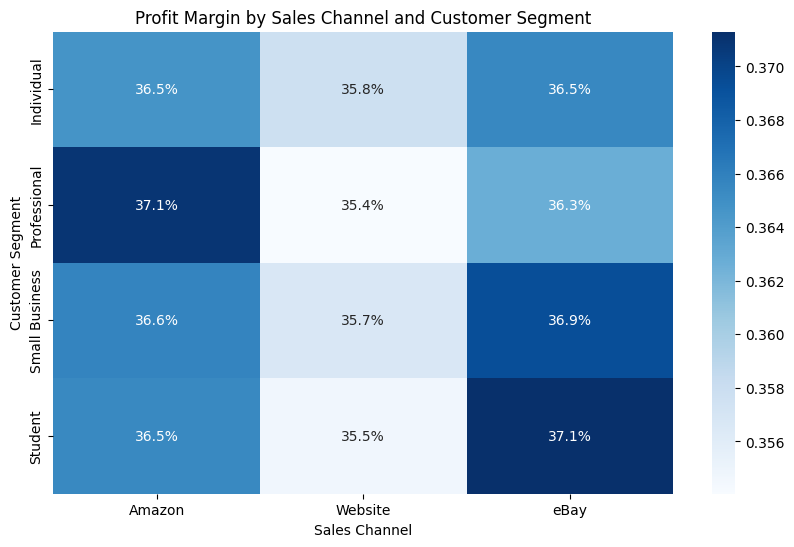

In [138]:
margin_pivot = channel_segment.pivot(
    index="Customer Segment",
    columns="Sales Channel",
    values="Profit Margin"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    margin_pivot,
    annot=True,
    fmt=".1%",
    cmap="Blues"
)

plt.title("Profit Margin by Sales Channel and Customer Segment")
plt.xlabel("Sales Channel")
plt.ylabel("Customer Segment")

plt.show()

**Findings - Sales Channel x Customer Segment**

The cross-analysis shows that profitability varies across customer segments and sales channels. Amazon has the highest profit margin for Individual and Professional customers, while eBay performs best for Small Business and Student customers. In contrast, Website records the lowest profit margin across all customer segments, despite generating substantial revenue. This suggests that Harbour & Co. should consider a more targeted channel strategy rather than applying the same approach across all customer segments.

**3. Discount x Sales Channel**

In [139]:
sales_analysis = sales.merge(
    products[["Product ID", "Unit Cost"]],
    on="Product ID",
    how="left"
)

sales_analysis["Revenue"] = (
    sales_analysis["Quantity"]
    * sales_analysis["Unit Price"]
    * (1 - sales_analysis["Discount"])
)

sales_analysis["Gross_Profit"] = (
    sales_analysis["Revenue"]
    - (sales_analysis["Quantity"] * sales_analysis["Unit Cost"])
    - sales_analysis["Shipping Cost"]
)

sales_analysis[[
    "Sales Channel",
    "Discount",
    "Revenue",
    "Gross_Profit"
]].head()

,Sales Channel,Discount,Revenue,Gross_Profit
0,Amazon,0.0,34.23,-5.75
1,Amazon,0.0,11.41,-5.02
2,Website,0.0,34.23,-8.21
3,Amazon,0.0,45.64,-25.49
4,Website,0.0,34.23,-10.52


In [140]:
discount_channel = (
    sales_analysis
    .groupby(["Sales Channel", "Discount"])
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)

discount_channel["Profit Margin"] = (
    discount_channel["Gross_Profit"] /
    discount_channel["Revenue"]
)

discount_channel

,Sales Channel,Discount,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
0,Amazon,0.00,10677,2.958754e+06,1.120459e+06,19308,0.378693
1,Amazon,0.05,259,7.274066e+04,2.555612e+04,484,0.351332
2,Amazon,0.10,261,5.913321e+04,1.709263e+04,454,0.289053
3,Amazon,0.15,1000,2.298409e+05,6.166390e+04,1735,0.268289
4,Amazon,0.20,283,6.368324e+04,1.469657e+04,503,0.230776
5,Website,0.00,17403,4.838260e+06,1.826829e+06,31631,0.377580
6,Website,0.05,426,1.166117e+05,4.088950e+04,768,0.350647
7,Website,0.10,5037,1.290894e+06,4.024022e+05,9145,0.311724
8,Website,0.15,2158,4.847138e+05,1.281961e+05,3784,0.264478
9,eBay,0.00,10951,3.076820e+06,1.163948e+06,20133,0.378296


In [141]:
import matplotlib.ticker as mtick

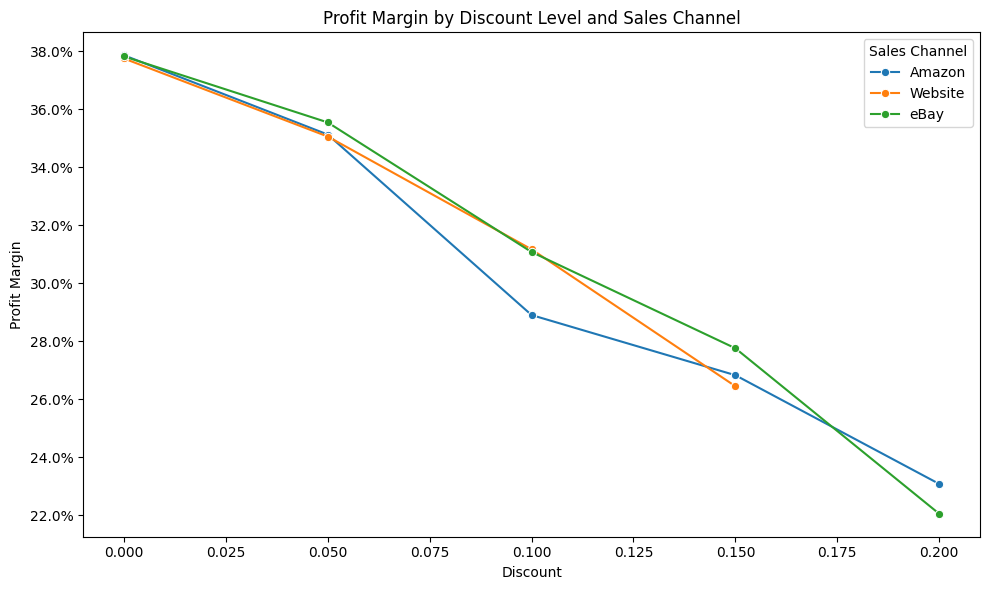

In [142]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=discount_channel,
    x="Discount",
    y="Profit Margin",
    hue="Sales Channel",
    marker="o"
)

plt.title("Profit Margin by Discount Level and Sales Channel")
plt.xlabel("Discount")
plt.ylabel("Profit Margin")
plt.gca().yaxis.set_major_formatter(
    mtick.PercentFormatter(1.0)
)

plt.legend(title="Sales Channel")
plt.tight_layout()
plt.show()

**Findings - Discount x Sales Channel**

Profit margin consistently decreases as discount increases across all channels: Amazon falls from 37.87% (0%) to 23.08% (20%), eBay from 37.83% to 22.05%, while Website drops from 37.76% (0%) to 26.45% (15%). This indicates that higher discounts are strongly associated with lower profitability.

**4. Product x Sales Channel**

In [143]:
product_channel = (
    sales_analysis
    .merge(
        products[["Product ID", "Product Name", "Category"]],
        on="Product ID",
        how="left"
    )
    .groupby(["Sales Channel", "Product Name"])
    .agg(
        Transactions=("Order ID", "count"),
        Revenue=("Revenue", "sum"),
        Gross_Profit=("Gross_Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)

product_channel["Profit Margin"] = (
    product_channel["Gross_Profit"] /
    product_channel["Revenue"]
)

product_channel.sort_values(
    "Gross_Profit",
    ascending=False
).head(20)

,Sales Channel,Product Name,Transactions,Revenue,Gross_Profit,Quantity,Profit Margin
354,Website,Smart Planner 09,592,291607.5330,108911.7630,1051,0.373487
207,Website,Classic Drawer Unit 16,462,200170.0800,86385.1500,821,0.431559
278,Website,Minimal Desk Mat 04,338,164990.4840,72756.8540,627,0.440976
180,Website,Adjustable Backpack 27,253,132252.6650,58985.1750,497,0.446004
305,Website,Modern Storage Box 09,228,119022.7655,57525.0855,411,0.483312
534,eBay,Smart Planner 09,253,141321.5790,54265.3890,502,0.383985
174,Amazon,Smart Planner 09,280,141766.2120,54088.7320,505,0.381535
255,Website,Ergonomic Task Light 08,254,130333.4240,52001.3740,442,0.398987
351,Website,Smart Mouse Pad 01,342,128372.6535,48808.4335,639,0.380209
27,Amazon,Classic Drawer Unit 16,246,109107.8580,48036.5080,441,0.440266


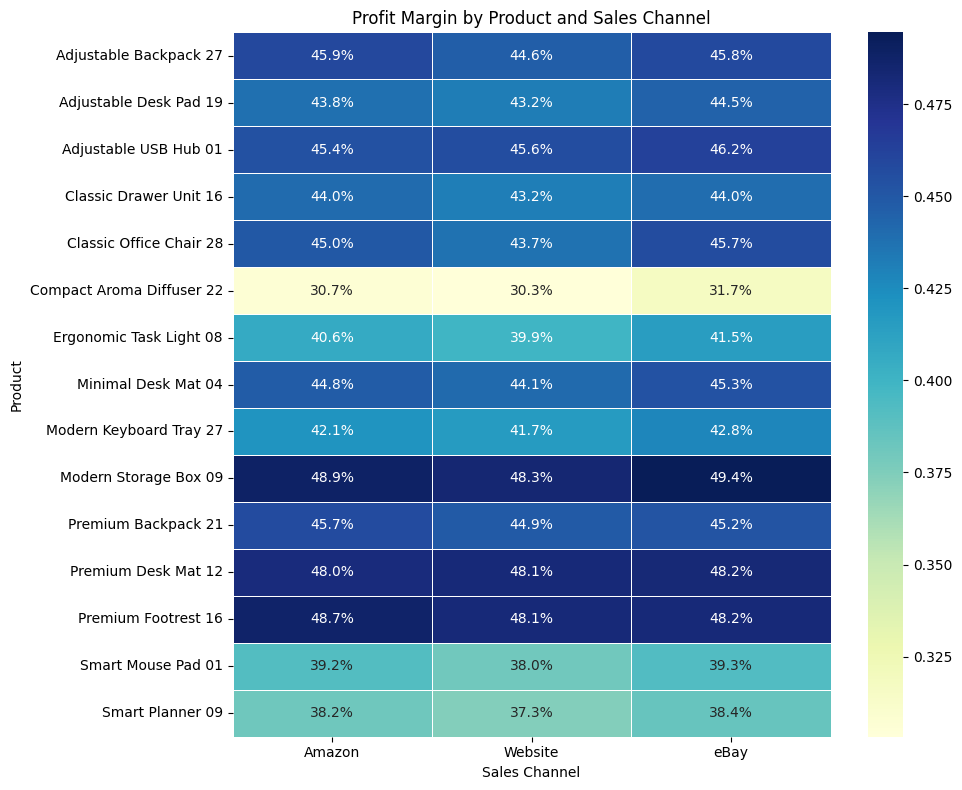

In [144]:
top_products = (
    product_channel
    .groupby("Product Name")["Gross_Profit"]
    .sum()
    .nlargest(15)
    .index
)

heatmap_data = (
    product_channel[
        product_channel["Product Name"].isin(top_products)
    ]
    .pivot(
        index="Product Name",
        columns="Sales Channel",
        values="Profit Margin"
    )
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1%",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Profit Margin by Product and Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Finding - Product x Sales Channel**

Profitability varies across product–channel combinations, with most products showing higher profit margins on Amazon and eBay than on the Website. Smart Planner 09 generates the highest gross profit on the Website at approximately $108.9K, followed by Classic Drawer Unit 16 at $86.4K. In contrast, Modern Storage Box 09 records consistently high profit margins across all channels, ranging from 48.3% on the Website to 49.4% on eBay. This suggests that Harbour & Co. should evaluate both total gross profit and profit margin when prioritising product–channel combinations for profitable growth.

**EDA Conclusion**

The exploratory data analysis indicates that Harbour & Co. has a stable and profitable business base, generating approximately $13.55 million in revenue and $4.90 million in gross profit at an overall margin of 36.15%. However, the analysis also identifies several opportunities to improve profitable growth. The Website generates the largest share of revenue but consistently records lower profit margins than Amazon and eBay, while deeper discounts and campaign activity are associated with substantial reductions in profitability. Product and geographic performance also vary, with high-margin products and stronger markets providing potential opportunities for targeted growth. In contrast, customer segments show relatively similar profitability and returns do not appear to be a major business-wide issue. Overall, the findings suggest that Harbour & Co.'s priority should not simply be to generate more sales, but to improve the profitability of existing sales through better channel management, disciplined discounting, targeted campaign strategies and greater focus on high-value product–channel combinations.`

# Business Insights

**Business Insight 1 - Harbour & Co. has a stable business base, but limited evidence of organic growth**

Harbour & Co. generated approximately $13.55 million in net revenue and $4.90 million in gross profit across 49,995 transactions, resulting in an overall profit margin of approximately 36.15%. Monthly performance remained relatively stable throughout the two-year period, with monthly revenue generally ranging from approximately $525,000 to $620,000 and profit margins fluctuating between approximately 34.5% and 37.8%. No clear long-term upward or downward trend was observed in revenue, transaction volume or profitability.

This indicates that Harbour & Co. has an established and relatively consistent revenue base rather than experiencing significant instability. However, the lack of a sustained upward trend also suggests that simply maintaining current operations may not generate substantial future growth. Therefore, the key opportunity is not to address a declining business, but to identify where existing revenue can be converted into more profitable growth through better channel, product and promotional decisions.

**Business Insight 2 - The Website is the main revenue channel but consistently underperforms on profitability**

The Website is Harbour & Co.'s largest sales channel, generating approximately $6.73 million in revenue, compared with $3.44 million through eBay and $3.38 million through Amazon. However, the Website records the lowest profit margin at 35.63%, compared with 36.70% for eBay and 36.63% for Amazon.

The cross-analysis reinforces this pattern. The Website records the lowest profit margin across every product category and across every customer segment analysed. For example, Website profit margins range from 32.44% to 37.11% across product categories, while Amazon and eBay generally achieve higher margins for the same categories. The same pattern is observed across customer segments, with Website margins ranging from approximately 35.4% to 35.8%.

This creates an important business opportunity: Harbour & Co. already has substantial customer and revenue volume on the Website, but this scale is not being converted into profitability as efficiently as the other channels. Management should therefore investigate the drivers of the Website margin gap, particularly discounting, product mix, shipping costs and channel-specific pricing or promotional practices, rather than simply attempting to increase Website sales volume.

**Business Insight 3 - Discounting and campaign activity are strongly associated with lower profitability**

Discounting represents one of the clearest profitability risks identified in the analysis. Transactions without discounts achieve a profit margin of approximately 37.81%, while transactions receiving 1–5% discounts achieve 35.21%, 6–10% discounts achieve 31.07%, and 11–20% discounts fall to only 25.69%.

The same pattern remains visible when discount levels are analysed by sales channel. For example, Amazon's profit margin decreases from 37.87% with no discount to 23.08% at a 20% discount, while eBay declines from 37.83% to 22.05%. Website profitability also falls from 37.76% at no discount to 26.45% at a 15% discount.

Campaign activity shows a similar pattern. Campaign-associated transactions generate a profit margin of 28.76%, compared with 37.40% for transactions without campaigns, representing an 8.64 percentage-point difference. Within campaigns, profit margin declines from 31.09% at a 10% discount to 22.33% at a 20% discount.

This suggests that Harbour & Co. may be sacrificing a significant amount of margin to generate discounted sales. However, these results indicate association rather than causation, because campaign transactions may differ in product mix, sales channel and other characteristics. The business should therefore evaluate promotions based on incremental profitable growth, rather than revenue or transaction volume alone

**Business Insight 4 - Product mix creates both major profit contributors and high-margin growth opportunities**


Product-level analysis shows that Harbour & Co.'s revenue and gross profit are concentrated among a relatively small number of products. Smart Planner 09 is the strongest product by scale, generating approximately $574.7K in revenue and $217.3K in gross profit. Classic Drawer Unit 16 follows with approximately $412.9K in revenue and $180.0K in gross profit.

However, products generating the most gross profit are not necessarily those with the highest profit margins. For example, Modern Storage Box 09 generates approximately $233.1K in revenue and $113.7K in gross profit, while achieving a strong 48.75% overall profit margin. The product–channel analysis further shows that Modern Storage Box 09 maintains margins of approximately 48.3% on Website, 48.9% on Amazon and 49.4% on eBay.

At the category level, Technology Accessories has the lowest profit margin at only 32.99%, compared with 37.58% for Storage & Organisation. Technology Accessories also remains the lowest-margin category across all three sales channels in the cross-analysis.

This indicates that Harbour & Co. should distinguish between scale products that generate large absolute profits and high-margin products that provide stronger profitability per dollar of revenue. A profitable growth strategy should identify opportunities to scale high-margin products while investigating whether low-margin categories such as Technology Accessories require pricing, sourcing, product mix or promotional adjustments.

**Business Insight 5 - Revenue is geographically concentrated, creating both a core-market opportunity and a profitability gap**

Harbour & Co.'s revenue is highly concentrated geographically. New South Wales, Victoria and Queensland collectively generate approximately 80% of total revenue, making these the company's core markets.

Victoria is particularly attractive because it combines substantial scale with strong profitability. It generates approximately $3.67 million in revenue and achieves the highest profit margin among the major markets at 37.63%. New South Wales generates the highest revenue at approximately $4.11 million, with a margin of 36.75%.

In contrast, Western Australia generates approximately $1.27 million in revenue but has a considerably lower profit margin of 32.48%. Northern Territory has an even lower margin of 27.94%, although its small transaction volume means this result should be interpreted cautiously.

The geographic analysis therefore suggests two different priorities. Harbour & Co. should protect and expand its strongest core markets, particularly Victoria, while investigating why profitability is lower in markets such as Western Australia. Geographic expansion should not be based solely on revenue potential; management should also assess the underlying profitability of each market.

**Business Insight 6 - Customer segment affects business scale more than profitability**

Customer segment performance is primarily driven by revenue scale rather than major differences in profitability. Individual customers are by far the largest segment, generating approximately $5.80 million in revenue and $2.10 million in gross profit. Students generate approximately $2.82 million, followed by Professionals at $2.50 million and Small Businesses at $2.39 million.

Despite these differences in scale, the known customer segments have remarkably similar profit margins:
- Individual: 36.14%
- Student: 36.17%
- Professional: 36.07%
- Small Business: 36.22%

The channel × customer segment analysis adds another layer: Website profitability remains the lowest across all customer segments, while Amazon and eBay perform relatively better depending on the segment.

This suggests that customer segment alone is not a major profitability differentiator for Harbour & Co. The greater opportunity lies in understanding which customer segments should be served through which channels and under what pricing or promotional conditions. Individual customers remain the largest opportunity for growth because of their substantial revenue contribution, but growth should be managed alongside channel and discount profitability.

**Supporting Business Insight - Returns are not currently a major constraint**

The analysis also identifies an important non-priority finding. Harbour & Co.'s overall return rate is only 1.81%, with relatively small differences across channels (1.68%–1.94%) and product categories (1.66%–1.98%).

Technology Accessories has the highest category return rate at 1.98%, but the difference from the lowest categories is small. Similarly, higher return rates observed in smaller geographic markets should be interpreted cautiously because of their lower transaction volumes.

Therefore, returns do not currently appear to be a major business-wide constraint. Management attention would likely generate greater value by focusing on channel profitability, discounting, campaign effectiveness and product mix.

**Overall Business Insights**

Taken together, the analysis suggests that Harbour & Co.'s main challenge is not insufficient sales volume or unstable performance. The business already has a relatively stable revenue base, substantial customer demand and several strong products and markets.

The more important issue is how efficiently the existing revenue base is converted into profit.

Three patterns are particularly important:
1. The Website generates the most revenue but consistently has lower margins than Amazon and eBay.
2. Higher discounts and campaign activity are consistently associated with substantially lower profit margins.
3. Profitability differs significantly by product and category, creating opportunities to shift attention toward stronger product–channel combinations.

At the same time, Harbour & Co. has clear strengths to build on, including high-performing products such as Smart Planner 09, high-margin products such as Modern Storage Box 09, strong markets such as Victoria, and a large Individual customer base.

Therefore, the central business opportunity is to move from a sales-volume-oriented approach toward a more profitability-oriented growth strategy.

# Recommendations

**Recommendation 1 — Improve Website Profitability**  
- Review Website transactions with low-margin products and high shipping/discount costs.
- Identify the main drivers of the Website's lower margin.
- Prioritise high-margin product–channel combinations on the Website.
- Target: gradually close the margin gap between Website and Amazon/eBay.

**Recommendation 2 — Introduce Discount Guardrails**  
- Set a maximum standard discount level for routine promotions.
- Require higher discounts to be justified by expected incremental sales.
- Track revenue, gross profit and profit margin for every campaign.
- Reduce reliance on 15–20% discounts where the additional sales do not compensate for lost margin.
- Target: protect margin while retaining effective promotions.

**Recommendation 3 — Prioritise High-Margin Products**  
- Create a monthly list of products ranked by Gross Profit + Profit Margin.
- Prioritise products such as Modern Storage Box 09 and other consistently high-margin products for promotion and inventory availability.
- Review low-margin categories such as Technology Accessories for pricing, supplier cost or product-mix improvements.
- Target: increase the contribution of high-margin products to overall gross profit.

**Recommendation 4 — Build a Profitability Monitoring Dashboard**  
- Use Power BI to monitor Revenue, Gross Profit, Profit Margin, Channel, Product, Category, Customer Segment, State and Discount Level.
- Add filters for channel, category, product and campaign.
- Include a small KPI section showing current performance against the overall 36.15% margin benchmark.
- Management can then identify margin deterioration without manually combining multiple Excel reports.
- Target: make profitability monitoring faster and more consistent.

In [145]:
# Export cleaned datasets for Power BI

sales.to_csv("sales_clean.csv", index=False)
products.to_csv("products_clean.csv", index=False)
customers.to_csv("customers_clean.csv", index=False)
campaigns.to_csv("campaigns_clean.csv", index=False)

print("Export completed successfully!")
print("Sales:", sales.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Campaigns:", campaigns.shape)

Export completed successfully!
Sales: (49995, 13)
Products: (180, 6)
Customers: (8000, 5)
Campaigns: (14, 7)


In [146]:
from google.colab import files

files.download("sales_clean.csv")
files.download("products_clean.csv")
files.download("customers_clean.csv")
files.download("campaigns_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>